<a href="https://colab.research.google.com/github/Taheri1400/paper_deeplearning/blob/main/paper_deeplearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
!pip install keras --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 16.1 MB/s  0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
      Successfully uninstalled keras-3.13.2


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [ ]:
import keras
print(keras.__version__)

3.15.1


In [ ]:
!pip install --upgrade --no-cache-dir gdown
!gdown 1jIl8uXsrdRz3ZBxljjQNo0ssDT8LbJBx

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2
Downloading...
From (original): https://drive.google.com/uc?id=1jIl8uXsrdRz3ZBxljjQNo0ssDT8LbJBx
From (redirected): https://drive.google.com/uc?id=1jIl8uXsrdRz3ZBxljjQNo0ssDT8LbJBx&confirm=t&uuid=d94cf64b-458f-479d-91e0-3f13df4463b3
To: /content/will_not_travel_again_data.zip
100% 188M/188M [00:03<00:00, 61.5MB/s]


In [ ]:
!unzip will_not_travel_again_data.zip

Archive:  will_not_travel_again_data.zip
   creating: data/
  inflating: data/test.csv           
  inflating: data/train.csv          


In [ ]:
import pandas as pd
import gc

df = pd.read_csv(
    'data/train.csv',
    engine='pyarrow'
)

test = pd.read_csv(
    'data/test.csv',
    engine='pyarrow'
)

In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325821 entries, 0 to 325820
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype        
---  ------                 --------------   -----        
 0                          325821 non-null  int64        
 1   user                   325821 non-null  int64        
 2   user_location_country  325821 non-null  int64        
 3   user_location_region   325821 non-null  int64        
 4   user_location_city     325821 non-null  int64        
 5   destination_distance   227151 non-null  float64      
 6   search_date            325821 non-null  datetime64[s]
 7   is_mobile              325821 non-null  int64        
 8   is_package             325821 non-null  int64        
 9   channel                325821 non-null  int64        
 10  search_count           325821 non-null  int64        
 11  checkIn_date           325821 non-null  object       
 12  checkOut_date          325821 non-null  object       
 13 

In [ ]:
print(df.shape)
print(df.columns.tolist())
print(df.head(10).to_string())
print(df.dtypes)

(7623000, 22)
['user', 'user_location_country', 'user_location_region', 'user_location_city', 'destination_distance', 'search_date', 'is_mobile', 'is_package', 'channel', 'search_count', 'checkIn_date', 'checkOut_date', 'n_adults', 'n_children', 'n_rooms', 'destination', 'destination_type', 'hotel_continent', 'hotel_country', 'hotel_market', 'hotel_category', 'is_booking']
      user  user_location_country  user_location_region  user_location_city  destination_distance         search_date  is_mobile  is_package  channel  search_count checkIn_date checkOut_date  n_adults  n_children  n_rooms  destination  destination_type  hotel_continent  hotel_country  hotel_market  hotel_category  is_booking
0   461899                      3                    50                5703                   NaN 2013-01-07 00:00:02          0           0        9             1   2013-03-14    2013-03-15         2           1        1          669                 3                2             50           21

In [ ]:

import pandas as pd
import numpy as np

# کپی گرفتن از داده‌ها
df = df.copy()
test = test.copy()

# حذف ستون اضافی ایندکس، در صورت وجود
for data in [df, test]:
    if 'Unnamed: 0' in data.columns:
        data.drop(columns=['Unnamed: 0'], inplace=True)

# تبدیل ستون‌های تاریخ
date_cols = ['search_date', 'checkIn_date', 'checkOut_date']

for data in [df, test]:
    for col in date_cols:
        data[col] = pd.to_datetime(data[col], errors='coerce')

    # مشخص کردن تاریخ‌های گمشده
    data['missing_checkin_date'] = data['checkIn_date'].isna().astype('int8')
    data['missing_checkout_date'] = data['checkOut_date'].isna().astype('int8')

    # فاصله زمانی تا تاریخ ورود
    data['days_until_checkin'] = (
        data['checkIn_date'] - data['search_date'].dt.normalize()
    ).dt.total_seconds() / 86400

    # مشخص کردن تاریخ ورود نامعتبر
    data['invalid_checkin_date'] = (
        data['days_until_checkin'] < 0
    ).fillna(False).astype('int8')

    # نسخه مناسب برای مدل؛ مقادیر منفی صفر می‌شوند
    data['days_until_checkin_model'] = (
        data['days_until_checkin'].clip(lower=0)
    )

    # مدت اقامت
    data['stay_duration'] = (
        data['checkOut_date'] - data['checkIn_date']
    ).dt.total_seconds() / 86400

    # مشخص کردن فاصله هتل گمشده
    data['distance_missing'] = (
        data['destination_distance'].isna().astype('int8')
    )

    # مشخص کردن مدت اقامت گمشده
    data['missing_stay_duration'] = (
        data['stay_duration'].isna().astype('int8')
    )

def missing_report(data, name):
    report = pd.DataFrame({
        'Missing_Count': data.isna().sum(),
        'Missing_Percent': data.isna().mean() * 100
    })

    report = report[report['Missing_Count'] > 0]
    report = report.sort_values(
        'Missing_Percent', ascending=False
    )

    print(f'\n{name} - Missing Values')
    print(f'Total rows: {len(data):,}')
    display(report.round(3))


missing_report(df, 'Main Dataset')
missing_report(test, 'Test Dataset')

print("Main Dataset:")
display(
    df[
        [
            'destination_distance',
            'days_until_checkin',
            'days_until_checkin_model',
            'stay_duration'
        ]
    ].describe().round(2)
)

print("\nInvalid check-in dates:")
print(df['invalid_checkin_date'].value_counts())

print("\nMissing stay duration:")
print(df['missing_stay_duration'].value_counts())



Main Dataset - Missing Values
Total rows: 7,623,000


,Missing_Count,Missing_Percent
destination_distance,2727207,35.776
checkIn_date,14292,0.187
checkOut_date,14292,0.187
days_until_checkin,14292,0.187
days_until_checkin_model,14292,0.187
stay_duration,14292,0.187



Test Dataset - Missing Values
Total rows: 325,821


,Missing_Count,Missing_Percent
destination_distance,98670,30.283


Main Dataset:


,destination_distance,days_until_checkin,days_until_checkin_model,stay_duration
count,4895793.00,7608708.00,7608708.00,7608708.00
mean,1936.55,48.19,48.19,3.29
std,2202.46,57.21,57.19,2.94
min,0.01,-348.00,0.00,0.00
25%,306.49,9.00,9.00,1.00
50%,1113.01,28.00,28.00,3.00
75%,2516.73,66.00,66.00,4.00
max,12280.48,516.00,516.00,370.00



Invalid check-in dates:
invalid_checkin_date
0    7621423
1       1577
Name: count, dtype: int64

Missing stay duration:
missing_stay_duration
0    7608708
1      14292
Name: count, dtype: int64


In [ ]:

# تقسیم زمانی دیتاست دارای برچسب

train = df[df['search_date'] < '2014-07-01'].copy()

valid = df[
    (df['search_date'] >= '2014-07-01') &
    (df['search_date'] < '2014-10-01')
].copy()

# نگهداری داده‌های بعد از بازه Validation
later_data = df[df['search_date'] >= '2014-10-01'].copy()

print("Train:", train.shape)
print("Validation:", valid.shape)
print("Later labeled data:", later_data.shape)
print("Separate Test:", test.shape)

print("\nDate ranges:")
print("Train:", train['search_date'].min(), "to", train['search_date'].max())
print("Validation:", valid['search_date'].min(), "to", valid['search_date'].max())
print("Later data:", later_data['search_date'].min(), "to", later_data['search_date'].max())
print("Separate Test:", test['search_date'].min(), "to", test['search_date'].max())


Train: (5940000, 30)
Validation: (1012000, 30)
Later labeled data: (671000, 30)
Separate Test: (325821, 30)

Date ranges:
Train: 2013-01-07 00:00:02 to 2014-06-30 23:59:51
Validation: 2014-07-01 00:00:25 to 2014-09-30 23:59:56
Later data: 2014-10-01 00:00:59 to 2014-11-30 23:59:39
Separate Test: 2014-12-01 00:01:11 to 2014-12-30 23:58:17


In [ ]:

# ستون‌هایی که باید مقادیر گمشده آن‌ها پر شود
numeric_cols = [
    'destination_distance',
    'days_until_checkin_model',
    'stay_duration'
]

# محاسبه میانه فقط از داده‌های Train
train_medians = train[numeric_cols].median()

print("Medians calculated from Train:")
print(train_medians)

# پر کردن مقادیر گمشده با میانه Train
datasets = [train, valid, later_data, test]

for data in datasets:
    for col in numeric_cols:
        data[col] = data[col].fillna(train_medians[col])

print("\nMissing values after imputation:")

for name, data in zip(
    ['Train', 'Validation', 'Later Data', 'Test'],
    datasets
):
    print(f"\n{name}:")
    print(data[numeric_cols].isna().sum())


Medians calculated from Train:
destination_distance        1200.7071
days_until_checkin_model      31.0000
stay_duration                  3.0000
dtype: float64

Missing values after imputation:

Train:
destination_distance        0
days_until_checkin_model    0
stay_duration               0
dtype: int64

Validation:
destination_distance        0
days_until_checkin_model    0
stay_duration               0
dtype: int64

Later Data:
destination_distance        0
days_until_checkin_model    0
stay_duration               0
dtype: int64

Test:
destination_distance        0
days_until_checkin_model    0
stay_duration               0
dtype: int64


In [ ]:

import pandas as pd
import numpy as np

# تمام مجموعه‌داده‌ها
datasets = {
    'train': train,
    'valid': valid,
    'later_data': later_data,
    'test': test
}

# استخراج ساعت و روز هفته از تاریخ جست‌وجو
for data in datasets.values():
    data['search_hour'] = data['search_date'].dt.hour
    data['search_dayofweek'] = data['search_date'].dt.dayofweek


# ویژگی‌های دسته‌ای
categorical_cols = [
    'user_location_country',
    'user_location_region',
    'user_location_city',
    'channel',
    'destination',
    'destination_type',
    'hotel_continent',
    'hotel_country',
    'hotel_market',
    'hotel_category',
    'search_hour',
    'search_dayofweek'
]


# ویژگی‌های عددی
numeric_cols = [
    'destination_distance',
    'is_mobile',
    'is_package',
    'search_count',
    'n_adults',
    'n_children',
    'n_rooms',
    'days_until_checkin_model',
    'stay_duration',
    'invalid_checkin_date',
    'missing_checkin_date',
    'missing_checkout_date',
    'distance_missing',
    'missing_stay_duration'
]


# تمام ویژگی‌های ورودی مدل
feature_cols = categorical_cols + numeric_cols


# بررسی وجود تمام ستون‌ها
for name, data in datasets.items():
    missing_cols = set(feature_cols) - set(data.columns)
    assert not missing_cols, f"{name}: Missing columns: {missing_cols}"


# تبدیل ویژگی‌های دسته‌ای به category
# دسته‌های Train مبنای تبدیل سایر مجموعه‌ها هستند.
unknown_counts = {}

for col in categorical_cols:

    train_values = pd.Index(train[col].dropna().unique())

    # انتخاب کدی که در دسته‌های Train وجود ندارد
    unknown_code = -1
    while unknown_code in train_values:
        unknown_code -= 1

    categories = train_values.append(pd.Index([unknown_code]))

    for name, data in datasets.items():

        known_mask = data[col].isin(train_values)
        unknown_counts.setdefault(name, {})[col] = (~known_mask).sum()

        mapped = data[col].where(known_mask, unknown_code)

        data[col] = pd.Categorical(
            mapped,
            categories=categories
        )


# نمایش نتیجه
print("Number of categorical features:", len(categorical_cols))
print("Number of numerical features:", len(numeric_cols))
print("Total features:", len(feature_cols))

print("\nCategorical feature types:")
print(train[categorical_cols].dtypes)

print("\nNumerical feature types:")
print(train[numeric_cols].dtypes)

print("\nUnknown categories in each dataset:")
display(pd.DataFrame(unknown_counts).T)


Number of categorical features: 12
Number of numerical features: 14
Total features: 26

Categorical feature types:
user_location_country    category
user_location_region     category
user_location_city       category
channel                  category
destination              category
destination_type         category
hotel_continent          category
hotel_country            category
hotel_market             category
hotel_category           category
search_hour              category
search_dayofweek         category
dtype: object

Numerical feature types:
destination_distance        float64
is_mobile                     int64
is_package                    int64
search_count                  int64
n_adults                      int64
n_children                    int64
n_rooms                       int64
days_until_checkin_model    float64
stay_duration               float64
invalid_checkin_date           int8
missing_checkin_date           int8
missing_checkout_date          int8
dista

,user_location_country,user_location_region,user_location_city,channel,destination,destination_type,hotel_continent,hotel_country,hotel_market,hotel_category,search_hour,search_dayofweek
train,0,0,0,0,0,0,0,0,0,0,0,0
valid,3,33,6563,0,4809,0,0,0,3,0,0,0
later_data,4,30,4561,0,3921,0,0,0,1,0,0,0
test,3,35,2250,0,2465,0,0,0,3,0,0,0


In [ ]:

import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
import gc

# چون داده‌ها قبلاً به Train، Validation و ... تقسیم شده‌اند،
# دیگر به DataFrame اصلی نیاز نداریم.
del df
gc.collect()


# ویژگی‌های عددی پیوسته که باید نرمال شوند
continuous_cols = [
    'destination_distance',
    'search_count',
    'n_adults',
    'n_children',
    'n_rooms',
    'days_until_checkin_model',
    'stay_duration'
]

# محاسبه میانگین و انحراف معیار فقط از Train
num_means = train[continuous_cols].mean()
num_stds = train[continuous_cols].std(ddof=0)

# جلوگیری از تقسیم بر صفر
num_stds = num_stds.replace(0, 1)

print("Means:")
print(num_means)

print("\nStandard deviations:")
print(num_stds)


# تابع تبدیل داده‌ها به آرایه‌های NumPy
def prepare_arrays(data, has_target=True):

    # تبدیل ویژگی‌های دسته‌ای به کد عددی
    X_cat = np.column_stack([
        data[col].cat.codes.to_numpy(dtype=np.int32)
        for col in categorical_cols
    ])

    # بررسی اینکه هیچ دسته‌ای کد منفی نداشته باشد
    assert (X_cat >= 0).all(), "Negative categorical code found!"

    # استخراج ویژگی‌های عددی
    X_num = data[numeric_cols].to_numpy(
        dtype=np.float32,
        copy=True
    )

    # نرمال‌سازی فقط ویژگی‌های پیوسته
    for col in continuous_cols:

        index = numeric_cols.index(col)

        X_num[:, index] = (
            X_num[:, index] - num_means[col]
        ) / num_stds[col]

    # متغیر هدف
    if has_target:
        y = data['is_booking'].to_numpy(
            dtype=np.float32
        ).reshape(-1, 1)

        return X_cat, X_num, y

    return X_cat, X_num


# آماده‌سازی Train
X_cat_train, X_num_train, y_train = prepare_arrays(train)

# آماده‌سازی Validation
X_cat_valid, X_num_valid, y_valid = prepare_arrays(valid)


print("Train:")
print("Categorical:", X_cat_train.shape)
print("Numerical:", X_num_train.shape)
print("Target:", y_train.shape)

print("\nValidation:")
print("Categorical:", X_cat_valid.shape)
print("Numerical:", X_num_valid.shape)
print("Target:", y_valid.shape)


# تعداد دسته‌های هر ویژگی برای ساخت Embedding
embedding_sizes = {
    col: len(train[col].cat.categories)
    for col in categorical_cols
}

print("\nEmbedding sizes:")
print(embedding_sizes)


Means:
destination_distance        1716.962880
search_count                   1.559583
n_adults                       2.013315
n_children                     0.379162
n_rooms                        1.112726
days_until_checkin_model      53.556478
stay_duration                  3.385418
dtype: float64

Standard deviations:
destination_distance        1821.889181
search_count                   1.304771
n_adults                       0.901818
n_children                     0.746564
n_rooms                        0.454189
days_until_checkin_model      61.679947
stay_duration                  3.009405
dtype: float64
Train:
Categorical: (5940000, 12)
Numerical: (5940000, 14)
Target: (5940000, 1)

Validation:
Categorical: (1012000, 12)
Numerical: (1012000, 14)
Target: (1012000, 1)

Embedding sizes:
{'user_location_country': 235, 'user_location_region': 964, 'user_location_city': 36891, 'channel': 12, 'destination': 38888, 'destination_type': 10, 'hotel_continent': 8, 'hotel_country': 212, 'ho

In [ ]:

# ساخت TensorDataset
train_dataset = TensorDataset(
    torch.from_numpy(X_cat_train),
    torch.from_numpy(X_num_train),
    torch.from_numpy(y_train)
)

valid_dataset = TensorDataset(
    torch.from_numpy(X_cat_valid),
    torch.from_numpy(X_num_valid),
    torch.from_numpy(y_valid)
)


# تنظیمات DataLoader
batch_size = 4096

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# بررسی دستگاه اجرا
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print("Device:", device)
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))


# بررسی اولین Batch
cat_batch, num_batch, y_batch = next(iter(train_loader))

print("\nFirst batch:")
print("Categorical:", cat_batch.shape, cat_batch.dtype)
print("Numerical:", num_batch.shape, num_batch.dtype)
print("Target:", y_batch.shape, y_batch.dtype)


Device: cuda
Train batches: 1451
Validation batches: 248

First batch:
Categorical: torch.Size([4096, 12]) torch.int32
Numerical: torch.Size([4096, 14]) torch.float32
Target: torch.Size([4096, 1]) torch.float32


In [ ]:

import torch
import torch.nn as nn


class BookingMLP(nn.Module):

    def __init__(self, embedding_sizes, num_numeric):

        super().__init__()

        # ساخت لایه‌های Embedding
        self.embeddings = nn.ModuleList()

        embedding_dimensions = []

        for num_categories in embedding_sizes.values():

            # تعیین اندازه بردار Embedding
            embedding_dim = min(50, (num_categories + 1) // 2)

            self.embeddings.append(
                nn.Embedding(
                    num_embeddings=num_categories,
                    embedding_dim=embedding_dim
                )
            )

            embedding_dimensions.append(embedding_dim)

        # تعداد کل ویژگی‌های ورودی پس از ترکیب
        input_size = sum(embedding_dimensions) + num_numeric

        # شبکه عصبی عمیق
        self.mlp = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(64, 1)
        )

    def forward(self, x_cat, x_num):

        # عبور هر ویژگی دسته‌ای از Embedding خودش
        embedded_features = []

        for i, embedding in enumerate(self.embeddings):

            embedded = embedding(x_cat[:, i].long())

            embedded_features.append(embedded)

        # ترکیب تمام Embeddingها
        x_cat_embedded = torch.cat(
            embedded_features,
            dim=1
        )

        # ترکیب ویژگی‌های دسته‌ای و عددی
        x = torch.cat(
            [x_cat_embedded, x_num],
            dim=1
        )

        # محاسبه خروجی شبکه
        return self.mlp(x)


# ساخت مدل
model = BookingMLP(
    embedding_sizes=embedding_sizes,
    num_numeric=len(numeric_cols)
)

# انتقال مدل به دستگاه اجرا
model = model.to(device)

# نمایش معماری
print(model)

# تعداد پارامترهای قابل یادگیری
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)


BookingMLP(
  (embeddings): ModuleList(
    (0): Embedding(235, 50)
    (1): Embedding(964, 50)
    (2): Embedding(36891, 50)
    (3): Embedding(12, 6)
    (4): Embedding(38888, 50)
    (5): Embedding(10, 5)
    (6): Embedding(8, 4)
    (7): Embedding(212, 50)
    (8): Embedding(2113, 50)
    (9): Embedding(101, 50)
    (10): Embedding(25, 13)
    (11): Embedding(8, 4)
  )
  (mlp): Sequential(
    (0): Linear(in_features=396, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.1, inplace=False)
    (11): Linear(in_features=64, out_features=1, b

In [ ]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled.")


CUDA available: True
GPU: Tesla T4


In [ ]:

import torch
import torch.nn as nn
import numpy as np

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# انتخاب GPU
device = torch.device('cuda')

# انتقال مدل به GPU
model = model.to(device)

# محاسبه وزن کلاس مثبت از Train
num_positive = train['is_booking'].sum()
num_negative = len(train) - num_positive

pos_weight = num_negative / num_positive

print("Positive samples:", num_positive)
print("Negative samples:", num_negative)
print("Positive class weight:", pos_weight)

# تابع خطا
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight],
        dtype=torch.float32,
        device=device
    )
)

# بهینه‌ساز
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("\nModel device:", next(model.parameters()).device)
print("Training setup completed.")


Positive samples: 525289
Negative samples: 5414711
Positive class weight: 10.30806089600201

Model device: cuda:0
Training setup completed.


In [ ]:

# تعداد Epochها
EPOCHS = 5

# تعداد Epochهای مجاز بدون بهبود
PATIENCE = 2

best_pr_auc = -1
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    train_loss = 0

    for x_cat, x_num, y in train_loader:

        # انتقال Batch به GPU
        x_cat = x_cat.to(
            device, dtype=torch.long, non_blocking=True
        )
        x_num = x_num.to(
            device, non_blocking=True
        )
        y = y.to(
            device, non_blocking=True
        )

        # صفر کردن گرادیان‌ها
        optimizer.zero_grad(set_to_none=True)

        # پیش‌بینی مدل
        logits = model(x_cat, x_num)

        # محاسبه خطا
        loss = criterion(logits, y)

        # محاسبه گرادیان‌ها
        loss.backward()

        # محدود کردن گرادیان‌ها
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        # به‌روزرسانی وزن‌ها
        optimizer.step()

        train_loss += loss.item() * len(y)

    train_loss /= len(train_dataset)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    valid_loss = 0
    all_probs = []
    all_targets = []

    with torch.no_grad():

        for x_cat, x_num, y in valid_loader:

            x_cat = x_cat.to(
                device, dtype=torch.long, non_blocking=True
            )
            x_num = x_num.to(
                device, non_blocking=True
            )
            y = y.to(
                device, non_blocking=True
            )

            logits = model(x_cat, x_num)

            loss = criterion(logits, y)

            valid_loss += loss.item() * len(y)

            # تبدیل خروجی خام شبکه به احتمال
            probs = torch.sigmoid(logits)

            all_probs.append(
                probs.squeeze(1).cpu().numpy()
            )

            all_targets.append(
                y.squeeze(1).cpu().numpy()
            )

    valid_loss /= len(valid_dataset)

    # ترکیب پیش‌بینی‌های Batchها
    y_true = np.concatenate(all_targets)
    y_probs = np.concatenate(all_probs)

    # معیارهای ارزیابی
    pr_auc = average_precision_score(y_true, y_probs)
    roc_auc = roc_auc_score(y_true, y_probs)

    logloss = log_loss(
        y_true,
        y_probs,
        labels=[0, 1]
    )

    brier = brier_score_loss(y_true, y_probs)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Weighted Loss: {train_loss:.5f}")
    print(f"Validation Weighted Loss: {valid_loss:.5f}")
    print(f"PR-AUC: {pr_auc:.5f}")
    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Log Loss: {logloss:.5f}")
    print(f"Brier Score: {brier:.5f}")

    # ذخیره بهترین مدل بر اساس PR-AUC
    if pr_auc > best_pr_auc:

        best_pr_auc = pr_auc
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            'best_booking_mlp.pt'
        )

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    # Early Stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activated.")
        break


# بارگذاری بهترین وزن‌های مدل
model.load_state_dict(
    torch.load(
        'best_booking_mlp.pt',
        map_location=device,
        weights_only=True
    )
)

print("\nTraining completed.")
print("Best Validation PR-AUC:", best_pr_auc)



Epoch 1/5
Train Weighted Loss: 1.02916
Validation Weighted Loss: 1.00476
PR-AUC: 0.18389
ROC-AUC: 0.75169
Log Loss: 0.67014
Brier Score: 0.24868
Best model saved.

Epoch 2/5
Train Weighted Loss: 0.99368
Validation Weighted Loss: 0.99050
PR-AUC: 0.18745
ROC-AUC: 0.75608
Log Loss: 0.63945
Brier Score: 0.23594
Best model saved.

Epoch 3/5
Train Weighted Loss: 0.98457
Validation Weighted Loss: 0.98279
PR-AUC: 0.18982
ROC-AUC: 0.75884
Log Loss: 0.62204
Brier Score: 0.22852
Best model saved.

Epoch 4/5
Train Weighted Loss: 0.97686
Validation Weighted Loss: 0.98533
PR-AUC: 0.19070
ROC-AUC: 0.75966
Log Loss: 0.63622
Brier Score: 0.23405
Best model saved.

Epoch 5/5
Train Weighted Loss: 0.96955
Validation Weighted Loss: 0.98472
PR-AUC: 0.19017
ROC-AUC: 0.75888
Log Loss: 0.62478
Brier Score: 0.22972

Training completed.
Best Validation PR-AUC: 0.19070003993373513


In [ ]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

model.eval()

all_logits = []
all_targets = []

# پیش‌بینی مجدد با بهترین مدل
with torch.no_grad():

    for x_cat, x_num, y in valid_loader:

        x_cat = x_cat.to(
            device, dtype=torch.long, non_blocking=True
        )
        x_num = x_num.to(
            device, non_blocking=True
        )

        logits = model(x_cat, x_num)

        all_logits.append(
            logits.squeeze(1).cpu().numpy()
        )

        all_targets.append(
            y.squeeze(1).numpy()
        )


# ترکیب نتایج Batchها
logits = np.concatenate(all_logits)
y_true = np.concatenate(all_targets)

# احتمال خام مدل
raw_probs = 1 / (
    1 + np.exp(-np.clip(logits, -50, 50))
)

# اصلاح اثر وزن کلاس مثبت
corrected_logits = logits - np.log(float(pos_weight))

corrected_probs = 1 / (
    1 + np.exp(-np.clip(corrected_logits, -50, 50))
)


# نرخ واقعی رزرو در Validation
booking_rate = y_true.mean()

# معیارهای ارزیابی
results = {
    'Validation booking rate': booking_rate,
    'Random baseline PR-AUC': booking_rate,
    'PR-AUC': average_precision_score(
        y_true, corrected_probs
    ),
    'ROC-AUC': roc_auc_score(
        y_true, corrected_probs
    ),
    'Log Loss (raw)': log_loss(
        y_true, raw_probs, labels=[0, 1]
    ),
    'Log Loss (corrected)': log_loss(
        y_true, corrected_probs, labels=[0, 1]
    ),
    'Brier Score (raw)': brier_score_loss(
        y_true, raw_probs
    ),
    'Brier Score (corrected)': brier_score_loss(
        y_true, corrected_probs
    )
}

print("Validation Evaluation:")
for metric, value in results.items():
    print(f"{metric}: {value:.5f}")


# بررسی کالیبراسیون در 10 گروه
calibration_df = pd.DataFrame({
    'predicted_probability': corrected_probs,
    'actual_booking': y_true
})

calibration_df['group'] = pd.qcut(
    calibration_df['predicted_probability'].rank(
        method='first'
    ),
    q=10,
    labels=False
)

calibration_table = (
    calibration_df.groupby('group')
    .agg(
        mean_predicted=('predicted_probability', 'mean'),
        actual_booking_rate=('actual_booking', 'mean'),
        samples=('actual_booking', 'size')
    )
)

print("\nCalibration by decile:")
display(calibration_table.round(4))


Validation Evaluation:
Validation booking rate: 0.07617
Random baseline PR-AUC: 0.07617
PR-AUC: 0.19070
ROC-AUC: 0.75966
Log Loss (raw): 0.63622
Log Loss (corrected): 0.23959
Brier Score (raw): 0.23405
Brier Score (corrected): 0.06656

Calibration by decile:


,mean_predicted,actual_booking_rate,samples
group,,,
0,0.0009,0.0006,101200
1,0.0056,0.0051,101200
2,0.0286,0.0208,101200
3,0.0553,0.0404,101200
4,0.0752,0.0551,101200
5,0.0957,0.0697,101200
6,0.1199,0.0882,101200
7,0.1502,0.1130,101200
8,0.1894,0.1468,101200


In [ ]:

import torch.nn.functional as F
from sklearn.metrics import log_loss

# نرخ واقعی رزرو در Validation
p_valid = y_true.mean()

# مدل ساده: همیشه نرخ متوسط رزرو را پیش‌بینی می‌کند
baseline_probs = np.full(
    len(y_true), p_valid
)

# وزن کلاس مثبت
w = float(pos_weight)

# بهترین پیش‌بینی ثابت برای Weighted BCE
baseline_q = (w * p_valid) / (
    (1 - p_valid) + w * p_valid
)

baseline_logit = np.log(
    baseline_q / (1 - baseline_q)
)

# محاسبه Weighted BCE مدل ساده
baseline_logits = torch.full(
    (len(y_true),),
    float(baseline_logit)
)

targets_tensor = torch.tensor(y_true, dtype=torch.float32)
logits_tensor = torch.tensor(logits, dtype=torch.float32)

baseline_weighted_loss = F.binary_cross_entropy_with_logits(
    baseline_logits,
    targets_tensor,
    pos_weight=torch.tensor([w])
).item()

model_weighted_loss = F.binary_cross_entropy_with_logits(
    logits_tensor,
    targets_tensor,
    pos_weight=torch.tensor([w])
).item()

print("Baseline Weighted Loss:", baseline_weighted_loss)
print("Our Model Weighted Loss:", model_weighted_loss)

print("\nBaseline Log Loss:",
      log_loss(y_true, baseline_probs))

print("Our Model Corrected Log Loss:",
      log_loss(y_true, corrected_probs))


Baseline Weighted Loss: 1.1789748668670654
Our Model Weighted Loss: 0.9853296875953674

Baseline Log Loss: 0.2693213632368224
Our Model Corrected Log Loss: 0.23959156371493084


In [ ]:

# ستون‌های لازم برای تشخیص جست‌وجوها
diag_cols = [
    'user',
    'search_date',
    'user_location_country',
    'user_location_region',
    'user_location_city',
    'destination',
    'checkIn_date',
    'checkOut_date',
    'is_mobile',
    'is_package',
    'channel',
    'search_count',
    'n_adults',
    'n_children',
    'n_rooms',
    'hotel_category',
    'is_booking'
]

# انتخاب یک بخش پیوسته از Train
n = min(200_000, len(train))
diag = train[diag_cols].iloc[:n].copy()

print("Rows examined:", len(diag))
print("Date range:")
print(diag['search_date'].min())
print(diag['search_date'].max())


# --------------------------------
# 1. بررسی زمان‌های دقیقاً یکسان
# --------------------------------

exact_groups = (
    diag.groupby(
        ['user', 'search_date'],
        observed=True
    )
    .size()
)

repeated_groups = exact_groups[exact_groups > 1]

print("\nExact user-time groups:", len(exact_groups))
print("Repeated user-time groups:", len(repeated_groups))
print("Rows in repeated groups:", repeated_groups.sum())

if len(repeated_groups) > 0:
    print("Maximum rows per exact user-time group:",
          repeated_groups.max())


# --------------------------------
# 2. بررسی جست‌وجوهای دارای مشخصات یکسان
# --------------------------------

signature_cols = [
    'user',
    'user_location_country',
    'user_location_region',
    'user_location_city',
    'destination',
    'checkIn_date',
    'checkOut_date',
    'is_mobile',
    'is_package',
    'channel',
    'search_count',
    'n_adults',
    'n_children',
    'n_rooms'
]

# مرتب‌سازی بر اساس مشخصات جست‌وجو و زمان
ordered = diag.sort_values(
    signature_cols + ['search_date']
)

# فاصله زمانی بین ردیف‌های دارای مشخصات جست‌وجوی یکسان
groups = ordered.groupby(
    signature_cols,
    observed=True,
    dropna=False,
    sort=False
)

ordered['gap_seconds'] = (
    groups['search_date']
    .diff()
    .dt.total_seconds()
)

gaps = ordered['gap_seconds'].dropna()

print("\nTime gaps between rows with the same search signature:")
print(gaps.describe())

print("\nPercentage of consecutive rows with identical search information:")

for seconds in [10, 60, 300, 1800]:
    percentage = (gaps <= seconds).mean() * 100
    print(f"Within {seconds} seconds: {percentage:.2f}%")


# --------------------------------
# 3. مشاهده ردیف‌های یک کاربر پرتکرار
# --------------------------------

most_frequent_user = diag['user'].value_counts().index[0]

user_history_sample = (
    diag[diag['user'] == most_frequent_user]
    .sort_values('search_date')
)

print("\nExample user:", most_frequent_user)
print("Number of rows:", len(user_history_sample))

display(
    user_history_sample[
        [
            'search_date',
            'destination',
            'checkIn_date',
            'checkOut_date',
            'search_count',
            'hotel_category',
            'is_booking'
        ]
    ].head(30)
)


Rows examined: 200000
Date range:
2013-01-07 00:00:02
2013-01-25 08:43:09

Exact user-time groups: 199981
Repeated user-time groups: 19
Rows in repeated groups: 38
Maximum rows per exact user-time group: 2

Time gaps between rows with the same search signature:
count    3.553200e+04
mean     1.793565e+04
std      8.846880e+04
min      0.000000e+00
25%      9.600000e+01
50%      2.380000e+02
75%      7.610000e+02
max      1.467799e+06
Name: gap_seconds, dtype: float64

Percentage of consecutive rows with identical search information:
Within 10 seconds: 1.81%
Within 60 seconds: 14.63%
Within 300 seconds: 55.81%
Within 1800 seconds: 84.91%

Example user: 1093415
Number of rows: 66


,search_date,destination,checkIn_date,checkOut_date,search_count,hotel_category,is_booking
50145,2013-01-11 15:05:09,4016,2013-05-15,2013-05-16,1,42,0
50988,2013-01-11 16:31:16,4016,2013-02-01,2013-02-08,1,90,0
51193,2013-01-11 16:51:03,25,2013-05-16,2013-05-17,3,10,0
51339,2013-01-11 17:04:37,8837,2013-05-18,2013-05-19,3,28,0
51377,2013-01-11 17:07:29,8837,2013-05-18,2013-05-19,1,16,0
51993,2013-01-11 18:02:09,8834,2013-05-19,2013-05-21,2,48,0
52255,2013-01-11 18:25:03,24292,2013-05-21,2013-05-22,4,91,0
52598,2013-01-11 18:56:22,11620,2013-05-22,2013-05-23,1,77,0
52640,2013-01-11 19:01:20,16449,2013-05-22,2013-05-23,3,13,0
52807,2013-01-11 19:16:58,13173,2013-05-25,2013-05-26,4,91,0


In [ ]:

# استفاده از همان 200 هزار ردیف برای بررسی
diag = train[[
    'user',
    'search_date',
    'user_location_country',
    'user_location_region',
    'user_location_city',
    'destination',
    'checkIn_date',
    'checkOut_date',
    'is_mobile',
    'is_package',
    'channel',
    'n_adults',
    'n_children',
    'n_rooms',
    'search_count',
    'hotel_category',
    'is_booking'
]].iloc[:200_000].copy()


# مشخصات اصلی درخواست جست‌وجو
query_cols = [
    'user',
    'user_location_country',
    'user_location_region',
    'user_location_city',
    'destination',
    'checkIn_date',
    'checkOut_date',
    'is_mobile',
    'is_package',
    'channel',
    'n_adults',
    'n_children',
    'n_rooms'
]


# مرتب‌سازی زمانی در هر گروه
ordered = diag.sort_values(
    query_cols + ['search_date']
).copy()


# محاسبه فاصله زمانی ردیف‌های متوالی با مشخصات یکسان
groups = ordered.groupby(
    query_cols,
    observed=True,
    dropna=False,
    sort=False
)

gaps = groups['search_date'].diff().dt.total_seconds()

# شروع نشست جدید در صورت فاصله بیشتر از 30 دقیقه
ordered['_new_session'] = (
    gaps.isna() | (gaps > 1800)
).astype('int8')

# شماره نشست در هر گروه جست‌وجوی مشابه
ordered['_session_no'] = (
    ordered.groupby(
        query_cols,
        observed=True,
        dropna=False,
        sort=False
    )['_new_session'].cumsum()
)


# مشخصات نشست‌های احتمالی
session_cols = query_cols + ['_session_no']

session_stats = (
    ordered.groupby(
        session_cols,
        observed=True,
        dropna=False
    )
    .agg(
        rows=('user', 'size'),
        start_time=('search_date', 'min'),
        end_time=('search_date', 'max'),
        hotel_categories=('hotel_category', 'nunique'),
        bookings=('is_booking', 'sum'),
        search_counts=('search_count', 'nunique')
    )
)

session_stats['duration_minutes'] = (
    session_stats['end_time'] -
    session_stats['start_time']
).dt.total_seconds() / 60


# گزارش نتایج
print("Total candidate sessions:", len(session_stats))

print(
    "\nSessions with multiple rows:",
    (session_stats['rows'] > 1).sum()
)

print(
    "Percentage of sessions with multiple rows:",
    (session_stats['rows'] > 1).mean() * 100
)

print(
    "\nPercentage of rows belonging to multi-row sessions:",
    session_stats.loc[
        session_stats['rows'] > 1, 'rows'
    ].sum() / len(ordered) * 100
)

print("\nRows per candidate session:")
display(session_stats['rows'].describe().round(2))

print("\nSession duration in minutes:")
display(session_stats['duration_minutes'].describe().round(2))

print(
    "\nSessions containing more than one booking:",
    (session_stats['bookings'] > 1).sum()
)

print(
    "\nSessions containing multiple hotel categories:",
    (session_stats['hotel_categories'] > 1).sum()
)

print("\nLargest candidate sessions:")
display(
    session_stats.sort_values(
        'rows', ascending=False
    ).head(15)
)


Total candidate sessions: 146315

Sessions with multiple rows: 34105
Percentage of sessions with multiple rows: 23.309298431466356

Percentage of rows belonging to multi-row sessions: 43.895

Rows per candidate session:


,rows
count,146315.00
mean,1.37
std,0.88
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,26.00



Session duration in minutes:


,duration_minutes
count,146315.00
mean,2.02
std,6.01
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,126.42



Sessions containing more than one booking: 17

Sessions containing multiple hotel categories: 27896

Largest candidate sessions:


,,,,,,,,,,,,,,rows,start_time,end_time,hotel_categories,bookings,search_counts,duration_minutes
user,user_location_country,user_location_region,user_location_city,destination,checkIn_date,checkOut_date,is_mobile,is_package,channel,n_adults,n_children,n_rooms,_session_no,,,,,,,
1054788,77,401,29226,8256,2013-06-28,2013-07-16,0,1,2,1,0,1,1,26,2013-01-24 03:35:49,2013-01-24 04:51:26,11,0,4,75.616667
824844,215,885,19561,8243,2013-02-14,2013-02-16,0,1,9,1,0,1,2,25,2013-01-24 12:00:24,2013-01-24 13:11:42,15,0,2,71.300000
905895,70,47,14566,12913,2013-01-20,2013-01-31,0,0,9,2,0,1,1,22,2013-01-14 22:26:13,2013-01-15 00:06:30,16,0,2,100.283333
203530,66,348,15357,8260,2013-03-14,2013-03-17,0,1,0,2,0,1,1,21,2013-01-09 14:14:14,2013-01-09 15:07:53,10,0,1,53.650000
324267,66,351,26084,8260,2013-03-27,2013-04-01,1,0,9,2,0,1,1,20,2013-01-24 21:44:09,2013-01-24 22:38:41,17,1,1,54.533333
448100,119,0,27731,8741,2013-02-06,2013-02-07,0,0,9,2,0,1,1,19,2013-01-19 19:39:52,2013-01-19 20:04:24,11,0,2,24.533333
230317,195,798,18282,8808,2013-05-29,2013-06-02,0,0,9,2,0,1,3,18,2013-01-09 21:15:58,2013-01-09 22:09:31,10,0,3,53.550000
254758,3,82,31921,20225,2013-02-09,2013-02-12,0,0,9,1,0,1,1,18,2013-01-17 00:01:32,2013-01-17 00:46:25,13,1,5,44.883333
1129921,66,363,16355,8268,2013-03-08,2013-03-13,0,0,9,2,0,1,1,18,2013-01-18 20:36:20,2013-01-18 22:30:47,10,0,3,114.450000


In [ ]:

# مرتب‌سازی Train بر اساس کاربر و زمان
train_history_check = (
    train[['user', 'search_date']]
    .sort_values(['user', 'search_date'])
    .copy()
)

# تعداد تعاملات قبلی هر کاربر در Train
# زمان‌های کاملاً یکسان، تعامل قبلی محسوب نمی‌شوند.
train_history_check['history_count'] = (
    train_history_check
    .groupby('user')['search_date']
    .rank(method='min')
    .astype('int32') - 1
)


# تعداد تعاملات هر کاربر در Train
train_user_counts = train['user'].value_counts()


# مرتب‌سازی Validation
valid_history_check = (
    valid[['user', 'search_date']]
    .sort_values(['user', 'search_date'])
    .copy()
)

# تعداد تعاملات قبلی همان کاربر در Validation
valid_history_check['previous_valid'] = (
    valid_history_check
    .groupby('user')['search_date']
    .rank(method='min')
    .astype('int32') - 1
)

# تعداد تعاملات قبلی در Train
valid_history_check['previous_train'] = (
    valid_history_check['user']
    .map(train_user_counts)
    .fillna(0)
    .astype('int32')
)

# مجموع تاریخچه در زمان هر پیش‌بینی
valid_history_check['history_count'] = (
    valid_history_check['previous_train'] +
    valid_history_check['previous_valid']
)


# تابع گزارش
def history_report(data, name):

    counts = data['history_count']

    print(f'\n{name}')
    print("Total rows:", len(data))

    print("No history:", (counts == 0).sum())
    print("1 to 4 previous events:",
          counts.between(1, 4).sum())
    print("5 to 9 previous events:",
          counts.between(5, 9).sum())
    print("10 or more previous events:",
          (counts >= 10).sum())

    print("\nHistory count statistics:")
    display(counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).round(2))


history_report(train_history_check, "Train")
history_report(valid_history_check, "Validation")


# بررسی کاربران جدید در Validation
train_users = set(train['user'].unique())
valid_users = set(valid['user'].unique())

new_users = valid_users - train_users

print("\nUsers seen in Train:", len(train_users))
print("Users in Validation:", len(valid_users))
print("New users in Validation:", len(new_users))
print("New user percentage:",
      len(new_users) / len(valid_users) * 100)



Train
Total rows: 5940000
No history: 761221
1 to 4 previous events: 1830713
5 to 9 previous events: 1156283
10 or more previous events: 2191783

History count statistics:


,history_count
count,5940000.00
mean,11.01
std,13.98
min,0.00
25%,2.00
50%,6.00
75%,15.00
90%,29.00
95%,40.00
max,192.00



Validation
Total rows: 1012000
No history: 126689
1 to 4 previous events: 297828
5 to 9 previous events: 186278
10 or more previous events: 401205

History count statistics:


,history_count
count,1012000.00
mean,12.46
std,15.87
min,0.00
25%,2.00
50%,6.00
75%,17.00
90%,34.00
95%,47.00
max,152.00



Users seen in Train: 761154
Users in Validation: 365571
New users in Validation: 126684
New user percentage: 34.65373347448239


In [ ]:

import numpy as np
import psutil
import gc

# حداکثر تعداد تعاملات قبلی
SEQ_LEN = 10

n_train = len(train)
n_valid = len(valid)
n_total = n_train + n_valid

# اطمینان از ترتیب زمانی Train و Validation
assert train['search_date'].max() < valid['search_date'].min()

# بررسی حافظه آزاد
available_gb = psutil.virtual_memory().available / (1024 ** 3)

estimated_history_mb = (
    n_total * SEQ_LEN * 4 / (1024 ** 2)
)

print(f"Available RAM: {available_gb:.2f} GB")
print(f"History index memory: {estimated_history_mb:.2f} MB")

if available_gb < 2:
    raise MemoryError(
        "RAM is low. Do not build history indices yet."
    )


# ترکیب شناسه کاربران و زمان جست‌وجو
users_all = np.concatenate([
    train['user'].to_numpy(dtype=np.int64),
    valid['user'].to_numpy(dtype=np.int64)
])

event_time_seconds = np.concatenate([
    train['search_date'].astype('int64').to_numpy(),
    valid['search_date'].astype('int64').to_numpy()
])


# مرتب‌سازی بر اساس کاربر و زمان
order = np.lexsort((
    event_time_seconds,
    users_all
))

sorted_users = users_all[order]
sorted_times = event_time_seconds[order]

N = len(order)
positions = np.arange(N, dtype=np.int64)


# تشخیص شروع هر کاربر
new_user = np.empty(N, dtype=bool)
new_user[0] = True

new_user[1:] = (
    sorted_users[1:] != sorted_users[:-1]
)

user_start = np.maximum.accumulate(
    np.where(new_user, positions, 0)
)


# تشخیص شروع هر گروه زمانی برای همان کاربر
new_block = new_user.copy()

new_block[1:] |= (
    sorted_times[1:] != sorted_times[:-1]
)

block_start = np.maximum.accumulate(
    np.where(new_block, positions, 0)
)


# تعداد تعاملات قبلی با زمان دقیقاً کوچک‌تر
available_history = block_start - user_start

history_length_sorted = np.minimum(
    available_history,
    SEQ_LEN
).astype(np.int8)


# ساخت ماتریس شماره ردیف‌های قبلی
# مقدار -1 نشان‌دهنده نبود تعامل قبلی است.
history_indices = np.full(
    (N, SEQ_LEN),
    -1,
    dtype=np.int32
)

# ترتیب تاریخچه از قدیمی به جدید است.
for slot in range(SEQ_LEN):

    mask = history_length_sorted > slot

    target_rows = order[mask]

    source_positions = (
        block_start[mask]
        - history_length_sorted[mask]
        + slot
    )

    history_indices[target_rows, slot] = (
        order[source_positions].astype(np.int32)
    )


# طول تاریخچه برای هر ردیف
history_lengths = np.zeros(N, dtype=np.int8)

history_lengths[order] = history_length_sorted


# آزاد کردن آرایه‌های موقت
del users_all, sorted_users, sorted_times
del order, positions, new_user, new_block
del user_start, block_start
del available_history, history_length_sorted

gc.collect()


# تفکیک آمار Train و Validation
train_history_lengths = history_lengths[:n_train]
valid_history_lengths = history_lengths[n_train:]


print("\nHistory construction completed.")

print("\nTrain history:")
print("No history:", (train_history_lengths == 0).sum())
print("Maximum history:", train_history_lengths.max())

print("\nValidation history:")
print("No history:", (valid_history_lengths == 0).sum())
print("Maximum history:", valid_history_lengths.max())


print("\nHistory index matrix:", history_indices.shape)
print("History index dtype:", history_indices.dtype)
print("Event time array:", event_time_seconds.shape)


Available RAM: 7.07 GB
History index memory: 265.20 MB

History construction completed.

Train history:
No history: 761221
Maximum history: 10

Validation history:
No history: 126689
Maximum history: 10

History index matrix: (6952000, 10)
History index dtype: int32
Event time array: (6952000,)


In [ ]:

import numpy as np
import gc

# ---------------------------------
# 1. ترکیب ویژگی‌های Train و Validation
# ---------------------------------

X_cat_all = np.concatenate(
    [X_cat_train, X_cat_valid],
    axis=0
)

X_num_all = np.concatenate(
    [X_num_train, X_num_valid],
    axis=0
)

y_all = np.concatenate(
    [y_train, y_valid],
    axis=0
)

print("Combined categorical:", X_cat_all.shape)
print("Combined numerical:", X_num_all.shape)
print("Combined target:", y_all.shape)


# ---------------------------------
# 2. محاسبه زمان دقیق تعاملات
# ---------------------------------

# تبدیل تاریخ‌ها به نانوثانیه برای محاسبه دقیق فاصله زمانی
event_time_ns = np.concatenate([
    train['search_date'].to_numpy(
        dtype='datetime64[ns]'
    ).astype(np.int64),

    valid['search_date'].to_numpy(
        dtype='datetime64[ns]'
    ).astype(np.int64)
])

# جایگزینی موقت -1 با صفر برای دسترسی به آرایه
safe_indices = np.maximum(
    history_indices,
    0
)

# زمان تعاملات تاریخی
history_times = event_time_ns[safe_indices]

# زمان تعامل فعلی
current_times = event_time_ns[:, None]

# فاصله زمانی بر حسب ساعت
time_gap_hours = (
    current_times - history_times
) / 3_600_000_000_000

# ماسک تعاملات معتبر
history_mask = history_indices >= 0

# بررسی اینکه هیچ تعامل آینده یا هم‌زمانی وارد تاریخچه نشده باشد
assert np.all(
    history_times[history_mask] <
    current_times.repeat(SEQ_LEN, axis=1)[history_mask]
)

# محاسبه لگاریتم فاصله زمانی
time_gap_log = np.zeros_like(
    time_gap_hours,
    dtype=np.float32
)

time_gap_log[history_mask] = np.log1p(
    time_gap_hours[history_mask]
)

print("\nTime gap statistics (hours):")

valid_gaps = time_gap_hours[history_mask]

print("Minimum:", valid_gaps.min())
print("Median:", np.median(valid_gaps))
print("Maximum:", valid_gaps.max())


# ---------------------------------
# 3. بررسی یک نمونه از تاریخچه
# ---------------------------------

sample_idx = np.where(history_lengths >= 3)[0][0]

print("\nExample row:", sample_idx)
print("History length:", history_lengths[sample_idx])

print("Previous row indices:")
print(history_indices[sample_idx])

print("Time gaps (log hours):")
print(time_gap_log[sample_idx])


print("\nAll checks passed successfully.")


Combined categorical: (6952000, 12)
Combined numerical: (6952000, 14)
Combined target: (6952000, 1)

Time gap statistics (hours):
Minimum: 0.0002777777777777778
Median: 647.7652777777778
Maximum: 15151.5975

Example row: 88
History length: 3
Previous row indices:
[70 79 82 -1 -1 -1 -1 -1 -1 -1]
Time gaps (log hours):
[0.07978626 0.05275057 0.03198304 0.         0.         0.
 0.         0.         0.         0.        ]

All checks passed successfully.


In [ ]:

import numpy as np
import torch
import torch.nn as nn
import copy
import gc

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

# اندازه مجموعه‌ها
n_train = len(train)
n_valid = len(valid)
n_total = n_train + n_valid

# نگهداری شناسه کاربران برای ارزیابی Cold Start در آینده
train_user_ids = np.unique(train['user'].to_numpy())

user_ids_all = np.concatenate([
    train['user'].to_numpy(dtype=np.int64),
    valid['user'].to_numpy(dtype=np.int64)
])

validation_new_user_mask = ~np.isin(
    valid['user'].to_numpy(),
    train_user_ids
)

# --------------------------------
# محاسبه آمار فاصله زمانی فقط از Train
# --------------------------------

gap_sum = 0.0
gap_squared_sum = 0.0
gap_count = 0

for start in range(0, n_train, 200_000):

    end = min(start + 200_000, n_train)

    mask = history_indices[start:end] >= 0

    values = time_gap_log[start:end][mask].astype(
        np.float64
    )

    gap_sum += values.sum()
    gap_squared_sum += np.square(values).sum()
    gap_count += len(values)

gap_mean = gap_sum / gap_count

gap_variance = (
    gap_squared_sum / gap_count - gap_mean ** 2
)

gap_std = np.sqrt(max(gap_variance, 1e-8))

print("Time gap mean:", gap_mean)
print("Time gap std:", gap_std)


# --------------------------------
# آزاد کردن آرایه‌های اضافی
# --------------------------------

cleanup_names = [
    'train_loader', 'valid_loader',
    'train_dataset', 'valid_dataset',
    'X_cat_train', 'X_num_train', 'y_train',
    'X_cat_valid', 'X_num_valid', 'y_valid',
    'time_gap_log', 'safe_indices',
    'history_times', 'current_times',
    'time_gap_hours', 'valid_gaps',
    'event_time_seconds',
    'train_history_check', 'valid_history_check',
    'user_history_sample', 'session_stats',
    'diag', 'ordered', 'groups',
    'exact_groups', 'repeated_groups',
    'train_users', 'valid_users'
]

for name in cleanup_names:
    if name in globals():
        del globals()[name]

# DataFrameهای Train و Validation دیگر برای ساخت Batch لازم نیستند
del train, valid

gc.collect()
torch.cuda.empty_cache()

print("\nAvailable RAM:",
      round(__import__('psutil').virtual_memory().available / 1024**3, 2),
      "GB")


# --------------------------------
# تابع ساخت هر Batch
# --------------------------------

def history_collate(batch):

    # شماره ردیف نمونه‌های فعلی
    indices = np.array(
        [item[0].item() for item in batch],
        dtype=np.int64
    )

    # شماره تعاملات تاریخی
    hist_idx = history_indices[indices]

    hist_mask = hist_idx >= 0

    # جایگزینی -1 موقتاً با صفر برای دسترسی به آرایه
    safe_idx = np.maximum(hist_idx, 0)

    # ویژگی‌های فعلی
    current_cat = X_cat_all[indices].copy()
    current_num = X_num_all[indices].copy()

    # ویژگی‌های تعاملات تاریخی
    hist_cat = X_cat_all[safe_idx].copy()
    hist_num = X_num_all[safe_idx].copy()

    # صفر کردن جایگاه‌های خالی تاریخچه
    hist_cat[~hist_mask] = 0
    hist_num[~hist_mask] = 0

    # فاصله زمانی تا تعامل فعلی
    delta_ns = (
        event_time_ns[indices][:, None] -
        event_time_ns[safe_idx]
    )

    delta_hours = np.maximum(
        delta_ns / 3_600_000_000_000,
        0
    )

    gap = np.log1p(delta_hours).astype(np.float32)

    # نرمال‌سازی با آمار Train
    gap = (gap - gap_mean) / gap_std

    # جایگاه‌های خالی همچنان صفر می‌مانند
    gap[~hist_mask] = 0

    # طول واقعی تاریخچه
    lengths = history_lengths[indices].astype(
        np.int64
    )

    # متغیر هدف
    targets = y_all[indices].copy()

    return (
        torch.from_numpy(current_cat),
        torch.from_numpy(current_num),
        torch.from_numpy(hist_cat),
        torch.from_numpy(hist_num),
        torch.from_numpy(gap),
        torch.from_numpy(lengths),
        torch.from_numpy(targets)
    )


# --------------------------------
# ساخت DataLoader
# --------------------------------

batch_size_gru = 1024

train_indices_dataset = TensorDataset(
    torch.arange(n_train, dtype=torch.long)
)

valid_indices_dataset = TensorDataset(
    torch.arange(n_train, n_total, dtype=torch.long)
)

train_gru_loader = DataLoader(
    train_indices_dataset,
    batch_size=batch_size_gru,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)

valid_gru_loader = DataLoader(
    valid_indices_dataset,
    batch_size=batch_size_gru,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)

print("\nTrain batches:", len(train_gru_loader))
print("Validation batches:", len(valid_gru_loader))

class BookingHistoryGRU(nn.Module):

    def __init__(
        self,
        baseline_model,
        num_numeric,
        gru_hidden=128
    ):

        super().__init__()

        # کپی کردن Embeddingهای مدل پایه
        self.embeddings = copy.deepcopy(
            baseline_model.embeddings
        )

        # کپی کردن لایه‌های MLP قبلی به جز لایه خروجی
        self.current_branch = copy.deepcopy(
            nn.Sequential(
                *list(baseline_model.mlp.children())[:-1]
            )
        )

        # ابعاد ورودی GRU
        embedding_dim = sum(
            layer.embedding_dim
            for layer in self.embeddings
        )

        gru_input_size = (
            embedding_dim + num_numeric + 1
        )

        # شبکه GRU برای تاریخچه کاربران
        self.gru = nn.GRU(
            input_size=gru_input_size,
            hidden_size=gru_hidden,
            num_layers=1,
            batch_first=True
        )

        # ترکیب اطلاعات فعلی و تاریخی
        current_dim = baseline_model.mlp[-1].in_features

        self.fusion = nn.Sequential(

            nn.Linear(
                current_dim + gru_hidden,
                128
            ),

            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 1)
        )

    def forward(
        self,
        x_cat,
        x_num,
        hist_cat,
        hist_num,
        hist_gap,
        lengths
    ):

        # -------------------------
        # شاخه اطلاعات فعلی
        # -------------------------

        current_embeddings = []

        for i, embedding in enumerate(self.embeddings):

            current_embeddings.append(
                embedding(x_cat[:, i].long())
            )

        current_embedded = torch.cat(
            current_embeddings,
            dim=1
        )

        current_input = torch.cat(
            [current_embedded, x_num],
            dim=1
        )

        current_output = self.current_branch(
            current_input
        )

        # -------------------------
        # شاخه تاریخچه
        # -------------------------

        history_embeddings = []

        for i, embedding in enumerate(self.embeddings):

            history_embeddings.append(
                embedding(hist_cat[:, :, i].long())
            )

        history_embedded = torch.cat(
            history_embeddings,
            dim=2
        )

        history_input = torch.cat(
            [
                history_embedded,
                hist_num,
                hist_gap.unsqueeze(-1)
            ],
            dim=2
        )

        # صفر کردن جایگاه‌های خالی
        positions = torch.arange(
            hist_cat.size(1),
            device=lengths.device
        ).unsqueeze(0)

        mask = positions < lengths.unsqueeze(1)

        history_input = (
            history_input * mask.unsqueeze(-1)
        )

        # GRU به طول واقعی توالی نیاز دارد.
        # برای کاربر بدون تاریخچه، طول را موقتاً 1 می‌کنیم.
        safe_lengths = lengths.clamp(min=1).cpu()

        packed_history = pack_padded_sequence(
            history_input,
            safe_lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed_history)

        history_output = hidden[-1]

        # خروجی تاریخچه کاربران بدون سابقه صفر می‌شود
        has_history = (
            lengths > 0
        ).to(history_output.dtype).unsqueeze(1)

        history_output = (
            history_output * has_history
        )

        # -------------------------
        # ترکیب دو شاخه
        # -------------------------

        combined = torch.cat(
            [current_output, history_output],
            dim=1
        )

        return self.fusion(combined)


# ساخت مدل تاریخچه‌محور
model_gru = BookingHistoryGRU(
    baseline_model=model,
    num_numeric=len(numeric_cols),
    gru_hidden=128
).to(device)

# انتقال مدل پایه به CPU برای آزاد شدن بخشی از حافظه GPU
model = model.to('cpu')
torch.cuda.empty_cache()


# تعداد پارامترهای مدل جدید
total_params = sum(
    p.numel()
    for p in model_gru.parameters()
    if p.requires_grad
)

print("Model device:", next(model_gru.parameters()).device)
print("Total trainable parameters:", total_params)
print(model_gru)

# دریافت یک Batch
batch = next(iter(train_gru_loader))

(
    x_cat,
    x_num,
    hist_cat,
    hist_num,
    hist_gap,
    lengths,
    targets
) = batch

# انتقال به GPU
x_cat = x_cat.to(device, dtype=torch.long)
x_num = x_num.to(device)

hist_cat = hist_cat.to(device, dtype=torch.long)
hist_num = hist_num.to(device)
hist_gap = hist_gap.to(device)

lengths = lengths.to(device)

# آزمایش مدل
model_gru.eval()

with torch.no_grad():

    output = model_gru(
        x_cat,
        x_num,
        hist_cat,
        hist_num,
        hist_gap,
        lengths
    )

print("Current categorical:", x_cat.shape)
print("Current numerical:", x_num.shape)

print("Historical categorical:", hist_cat.shape)
print("Historical numerical:", hist_num.shape)
print("Historical time gaps:", hist_gap.shape)
print("History lengths:", lengths.shape)

print("\nModel output:", output.shape)
print("All outputs finite:", torch.isfinite(output).all().item())

print(
    "GPU memory used:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Time gap mean: 5.359028744082906
Time gap std: 2.8970666162494276

Available RAM: 6.61 GB

Train batches: 5801
Validation batches: 989
Model device: cuda:0
Total trainable parameters: 4341720
BookingHistoryGRU(
  (embeddings): ModuleList(
    (0): Embedding(235, 50)
    (1): Embedding(964, 50)
    (2): Embedding(36891, 50)
    (3): Embedding(12, 6)
    (4): Embedding(38888, 50)
    (5): Embedding(10, 5)
    (6): Embedding(8, 4)
    (7): Embedding(212, 50)
    (8): Embedding(2113, 50)
    (9): Embedding(101, 50)
    (10): Embedding(25, 13)
    (11): Embedding(8, 4)
  )
  (current_branch): Sequential(
    (0): Linear(in_features=396, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReL

ValueError: RNN input dtype (torch.float64) does not match weight dtype (torch.float32). Convert input: input.to(torch.float32), or convert model: model.to(torch.float64)

In [ ]:

# نگهداری تابع قبلی
old_history_collate = history_collate

# اصلاح نوع داده فاصله زمانی
def history_collate(batch):

    result = list(old_history_collate(batch))

    # تبدیل hist_gap به float32
    result[4] = result[4].to(torch.float32)

    return tuple(result)


# ساخت مجدد DataLoader با تابع اصلاح‌شده
train_gru_loader = DataLoader(
    train_indices_dataset,
    batch_size=batch_size_gru,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)

valid_gru_loader = DataLoader(
    valid_indices_dataset,
    batch_size=batch_size_gru,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)


# دریافت یک Batch جدید
batch = next(iter(train_gru_loader))

(
    x_cat,
    x_num,
    hist_cat,
    hist_num,
    hist_gap,
    lengths,
    targets
) = batch


# بررسی نوع داده‌ها
print("Current numerical:", x_num.dtype)
print("History numerical:", hist_num.dtype)
print("History time gaps:", hist_gap.dtype)


# انتقال داده‌ها به GPU
x_cat = x_cat.to(device, dtype=torch.long)
x_num = x_num.to(device)

hist_cat = hist_cat.to(device, dtype=torch.long)
hist_num = hist_num.to(device)
hist_gap = hist_gap.to(device)

lengths = lengths.to(device)


# آزمایش مدل
model_gru.eval()

with torch.no_grad():

    output = model_gru(
        x_cat,
        x_num,
        hist_cat,
        hist_num,
        hist_gap,
        lengths
    )

print("\nModel output:", output.shape)
print("All outputs finite:",
      torch.isfinite(output).all().item())

print(
    "GPU memory used:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Current numerical: torch.float32
History numerical: torch.float32
History time gaps: torch.float32

Model output: torch.Size([1024, 1])
All outputs finite: True
GPU memory used: 0.15 GB


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# --------------------------------
# 1. تنظیمات اولیه
# --------------------------------

device = torch.device('cuda')

model_gru = model_gru.to(device)

BATCH_SIZE = 2048
EPOCHS = 5
PATIENCE = 2

# محاسبه وزن کلاس مثبت فقط از Train
train_targets = y_all[:n_train]

num_positive_gru = train_targets.sum()
num_negative_gru = len(train_targets) - num_positive_gru

pos_weight_gru = float(
    num_negative_gru / num_positive_gru
)

print("Positive weight:", pos_weight_gru)


# --------------------------------
# 2. بازسازی DataLoader
# --------------------------------

train_gru_loader = DataLoader(
    train_indices_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)

valid_gru_loader = DataLoader(
    valid_indices_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=history_collate
)

print("Train batches:", len(train_gru_loader))
print("Validation batches:", len(valid_gru_loader))


# --------------------------------
# 3. تابع خطا
# --------------------------------

criterion_gru = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight_gru],
        dtype=torch.float32,
        device=device
    )
)


# --------------------------------
# 4. بهینه‌ساز با دو نرخ یادگیری
# --------------------------------

optimizer_gru = torch.optim.AdamW(
    [
        {
            'params': list(model_gru.embeddings.parameters())
                      + list(model_gru.current_branch.parameters()),
            'lr': 0.0001
        },
        {
            'params': list(model_gru.gru.parameters())
                      + list(model_gru.fusion.parameters()),
            'lr': 0.0003
        }
    ],
    weight_decay=1e-5
)


# --------------------------------
# 5. شروع آموزش
# --------------------------------

best_pr_auc_gru = -1
epochs_without_improvement = 0

best_valid_logits_gru = None
y_true_gru = y_all[n_train:].reshape(-1).copy()

for epoch in range(EPOCHS):

    # ============================
    # Training
    # ============================

    model_gru.train()

    total_train_loss = 0

    for batch_idx, batch in enumerate(train_gru_loader):

        (
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths,
            targets
        ) = batch

        # انتقال داده‌ها به GPU
        x_cat = x_cat.to(
            device, dtype=torch.long, non_blocking=True
        )

        x_num = x_num.to(
            device, non_blocking=True
        )

        hist_cat = hist_cat.to(
            device, dtype=torch.long, non_blocking=True
        )

        hist_num = hist_num.to(
            device, non_blocking=True
        )

        hist_gap = hist_gap.to(
            device, non_blocking=True
        )

        lengths = lengths.to(device)

        targets = targets.to(
            device, non_blocking=True
        )

        # صفر کردن گرادیان‌ها
        optimizer_gru.zero_grad(set_to_none=True)

        # پیش‌بینی مدل
        logits = model_gru(
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths
        )

        # محاسبه Loss
        loss = criterion_gru(logits, targets)

        # محاسبه گرادیان‌ها
        loss.backward()

        # کنترل مقدار گرادیان‌ها
        torch.nn.utils.clip_grad_norm_(
            model_gru.parameters(),
            max_norm=1.0
        )

        # به‌روزرسانی وزن‌ها
        optimizer_gru.step()

        total_train_loss += loss.item() * len(targets)

        # گزارش پیشرفت آموزش
        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Batch {batch_idx + 1}/{len(train_gru_loader)}"
            )

    train_loss_gru = total_train_loss / n_train


    # ============================
    # Validation
    # ============================

    model_gru.eval()

    total_valid_loss = 0
    valid_logits_list = []

    with torch.no_grad():

        for batch in valid_gru_loader:

            (
                x_cat,
                x_num,
                hist_cat,
                hist_num,
                hist_gap,
                lengths,
                targets
            ) = batch

            x_cat = x_cat.to(
                device, dtype=torch.long, non_blocking=True
            )

            x_num = x_num.to(
                device, non_blocking=True
            )

            hist_cat = hist_cat.to(
                device, dtype=torch.long, non_blocking=True
            )

            hist_num = hist_num.to(
                device, non_blocking=True
            )

            hist_gap = hist_gap.to(
                device, non_blocking=True
            )

            lengths = lengths.to(device)

            targets = targets.to(
                device, non_blocking=True
            )

            logits = model_gru(
                x_cat,
                x_num,
                hist_cat,
                hist_num,
                hist_gap,
                lengths
            )

            loss = criterion_gru(logits, targets)

            total_valid_loss += loss.item() * len(targets)

            valid_logits_list.append(
                logits.squeeze(1).cpu().numpy()
            )

    valid_loss_gru = total_valid_loss / n_valid

    # ترکیب پیش‌بینی‌ها
    valid_logits_gru = np.concatenate(valid_logits_list)

    # اصلاح اثر وزن کلاس مثبت
    corrected_logits = (
        valid_logits_gru - np.log(pos_weight_gru)
    )

    corrected_logits = np.clip(
        corrected_logits, -50, 50
    )

    valid_probs_gru = 1 / (
        1 + np.exp(-corrected_logits)
    )

    # معیارهای ارزیابی
    pr_auc_gru = average_precision_score(
        y_true_gru,
        valid_probs_gru
    )

    roc_auc_gru = roc_auc_score(
        y_true_gru,
        valid_probs_gru
    )

    logloss_gru = log_loss(
        y_true_gru,
        valid_probs_gru,
        labels=[0, 1]
    )

    brier_gru = brier_score_loss(
        y_true_gru,
        valid_probs_gru
    )

    print(f"\n========== Epoch {epoch + 1}/{EPOCHS} ==========")

    print(f"Train Weighted Loss: {train_loss_gru:.5f}")
    print(f"Validation Weighted Loss: {valid_loss_gru:.5f}")
    print(f"PR-AUC: {pr_auc_gru:.5f}")
    print(f"ROC-AUC: {roc_auc_gru:.5f}")
    print(f"Log Loss (corrected): {logloss_gru:.5f}")
    print(f"Brier Score (corrected): {brier_gru:.5f}")

    # ذخیره بهترین مدل
    if pr_auc_gru > best_pr_auc_gru:

        best_pr_auc_gru = pr_auc_gru
        epochs_without_improvement = 0

        best_valid_logits_gru = valid_logits_gru.copy()

        torch.save(
            model_gru.state_dict(),
            'best_booking_gru.pt'
        )

        print("Best GRU model saved.")

    else:

        epochs_without_improvement += 1

    # توقف زودهنگام
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activated.")
        break


# --------------------------------
# 6. بارگذاری بهترین مدل
# --------------------------------

model_gru.load_state_dict(
    torch.load(
        'best_booking_gru.pt',
        map_location=device,
        weights_only=True
    )
)

model_gru.eval()

print("\nGRU training completed.")
print("Best Validation PR-AUC:", best_pr_auc_gru)


Positive weight: 10.308060646057129
Train batches: 2901
Validation batches: 495
Epoch 1 | Batch 500/2901
Epoch 1 | Batch 1000/2901
Epoch 1 | Batch 1500/2901
Epoch 1 | Batch 2000/2901
Epoch 1 | Batch 2500/2901

========== Epoch 1/5 ==========
Train Weighted Loss: 0.94878
Validation Weighted Loss: 0.96555
PR-AUC: 0.20358
ROC-AUC: 0.76663
Log Loss (corrected): 0.23585
Brier Score (corrected): 0.06581
Best GRU model saved.
Epoch 2 | Batch 500/2901
Epoch 2 | Batch 1000/2901
Epoch 2 | Batch 1500/2901
Epoch 2 | Batch 2000/2901
Epoch 2 | Batch 2500/2901

========== Epoch 2/5 ==========
Train Weighted Loss: 0.93184
Validation Weighted Loss: 0.96239
PR-AUC: 0.20608
ROC-AUC: 0.76901
Log Loss (corrected): 0.23555
Brier Score (corrected): 0.06587
Best GRU model saved.
Epoch 3 | Batch 500/2901
Epoch 3 | Batch 1000/2901
Epoch 3 | Batch 1500/2901
Epoch 3 | Batch 2000/2901
Epoch 3 | Batch 2500/2901

========== Epoch 3/5 ==========
Train Weighted Loss: 0.92202
Validation Weighted Loss: 0.96231
PR-AUC: 0

In [ ]:
mlp = {
"Train Weighted Loss":0.97686,
"Validation Weighted Loss":0.98533,
"PR-AUC":0.19070003993373513,
"ROC-AUC":0.75966,
"Corrected Log Loss":0.23959156371493084,
"Corrected Brier Score":0.06656
}
gru = {
"Train Weighted Loss":0.89985,
"Validation Weighted Loss":0.96264,
"PR-AUC":0.211871254538045,
"ROC-AUC":0.77025,
"Corrected Log Loss":0.23508,
"Corrected Brier Score":0.06561
}
for k in mlp:
    if "Loss" in k or "Brier" in k:
        imp=(mlp[k]-gru[k])/mlp[k]*100
    else:
        imp=(gru[k]-mlp[k])/mlp[k]*100
    print(k, imp)


Train Weighted Loss 7.883422394201823
Validation Weighted Loss 2.302781809140084
PR-AUC 11.10184067694296
ROC-AUC 1.3940447042097763
Corrected Log Loss 1.8830227763356269
Corrected Brier Score 1.4272836538461426


In [ ]:

import pandas as pd
import numpy as np

# نتایج بهترین MLP
mlp_results = {
    'Train Weighted Loss': 0.97686,
    'Validation Weighted Loss': 0.98533,
    'PR-AUC': 0.19070003993373513,
    'ROC-AUC': 0.75966,
    'Corrected Log Loss': 0.23959156371493084,
    'Corrected Brier Score': 0.06656
}

# نتایج بهترین MLP + GRU
gru_results = {
    'Train Weighted Loss': 0.89985,
    'Validation Weighted Loss': 0.96264,
    'PR-AUC': 0.211871254538045,
    'ROC-AUC': 0.77025,
    'Corrected Log Loss': 0.23508,
    'Corrected Brier Score': 0.06561
}

# جدول مقایسه
comparison = pd.DataFrame({
    'MLP': mlp_results,
    'MLP + GRU': gru_results
})

# تعیین جهت بهبود
higher_is_better = ['PR-AUC', 'ROC-AUC']

improvements = []

for metric in comparison.index:

    mlp_value = comparison.loc[metric, 'MLP']
    gru_value = comparison.loc[metric, 'MLP + GRU']

    if metric in higher_is_better:
        improvement = (
            (gru_value - mlp_value) / mlp_value
        ) * 100
    else:
        improvement = (
            (mlp_value - gru_value) / mlp_value
        ) * 100

    improvements.append(improvement)

comparison['Improvement (%)'] = improvements

print("Comparison of MLP and MLP + GRU:")
display(comparison.round(5))

print("\nRandom baseline PR-AUC: 0.07617")


Comparison of MLP and MLP + GRU:


,MLP,MLP + GRU,Improvement (%)
Train Weighted Loss,0.97686,0.89985,7.88342
Validation Weighted Loss,0.98533,0.96264,2.30278
PR-AUC,0.19070,0.21187,11.10184
ROC-AUC,0.75966,0.77025,1.39404
Corrected Log Loss,0.23959,0.23508,1.88302
Corrected Brier Score,0.06656,0.06561,1.42728



Random baseline PR-AUC: 0.07617


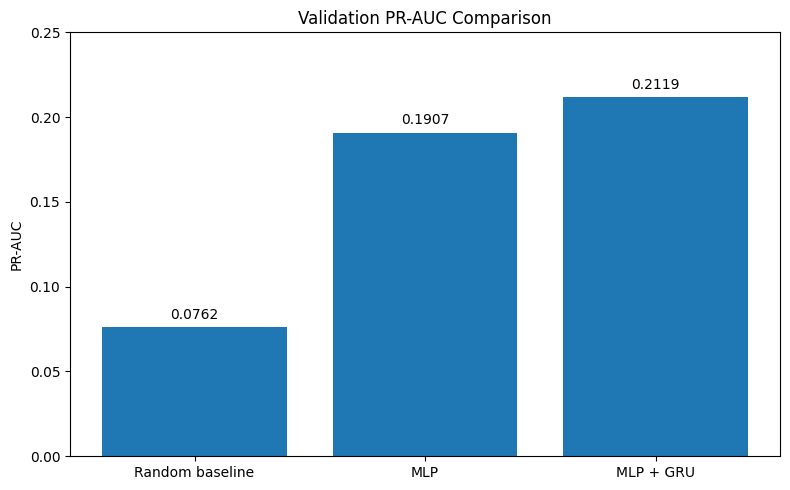

In [ ]:

import matplotlib.pyplot as plt

models = [
    'Random baseline',
    'MLP',
    'MLP + GRU'
]

pr_values = [
    0.07617,
    mlp_results['PR-AUC'],
    gru_results['PR-AUC']
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, pr_values)

plt.ylabel('PR-AUC')
plt.title('Validation PR-AUC Comparison')
plt.ylim(0, 0.25)

for bar, value in zip(bars, pr_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f'{value:.4f}',
        ha='center'
    )

plt.tight_layout()
plt.show()


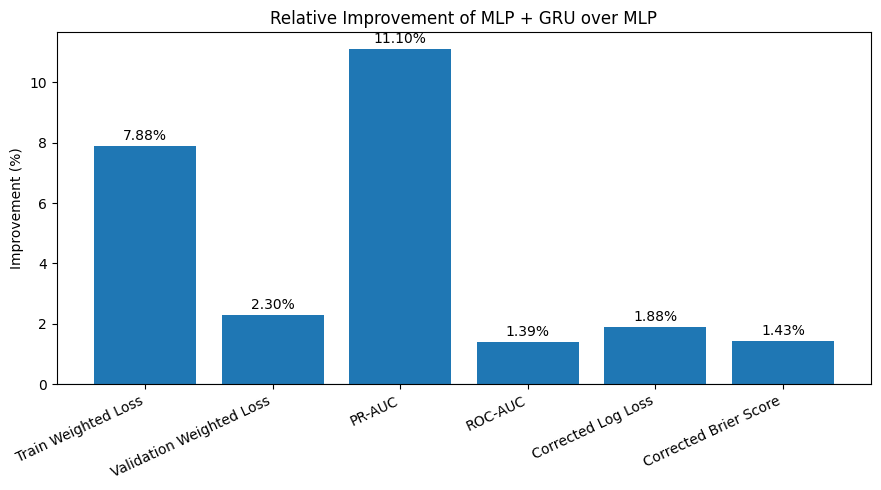

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison.index,
    comparison['Improvement (%)']
)

plt.axhline(0, linewidth=0.8)

plt.ylabel('Improvement (%)')
plt.title('Relative Improvement of MLP + GRU over MLP')

plt.xticks(rotation=25, ha='right')

for i, value in enumerate(comparison['Improvement (%)']):

    plt.text(
        i,
        value + 0.2,
        f'{value:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# متغیر هدف Validation
y_eval = y_all[n_train:].reshape(-1).astype(np.int8)

# تعداد نمونه‌های Validation
assert len(y_eval) == n_valid

# --------------------------------
# 1. پیش‌بینی‌های MLP
# --------------------------------

if (
    'corrected_probs' in globals()
    and len(corrected_probs) == n_valid
):
    mlp_probs = np.asarray(corrected_probs).reshape(-1)

    print("Using previously calculated MLP predictions.")

else:

    print("Calculating MLP predictions again...")

    pos_weight_mlp = (
        (y_all[:n_train] == 0).sum() /
        (y_all[:n_train] == 1).sum()
    )

    model = model.to(device)
    model.eval()

    mlp_logits_list = []

    with torch.no_grad():

        for start in range(n_train, n_total, 8192):

            end = min(start + 8192, n_total)

            cat = torch.from_numpy(
                X_cat_all[start:end]
            ).to(device, dtype=torch.long)

            num = torch.from_numpy(
                X_num_all[start:end]
            ).to(device)

            logits = model(cat, num)

            mlp_logits_list.append(
                logits.squeeze(1).cpu().numpy()
            )

    mlp_logits = np.concatenate(mlp_logits_list)

    mlp_probs = 1 / (
        1 + np.exp(-np.clip(
            mlp_logits - np.log(pos_weight_mlp),
            -50, 50
        ))
    )

    model = model.cpu()
    torch.cuda.empty_cache()


# --------------------------------
# 2. پیش‌بینی‌های بهترین GRU
# --------------------------------

gru_logits = np.asarray(
    best_valid_logits_gru
).reshape(-1)

# اصلاح اثر وزن کلاس مثبت
gru_corrected_logits = (
    gru_logits - np.log(float(pos_weight_gru))
)

gru_probs = 1 / (
    1 + np.exp(-np.clip(
        gru_corrected_logits,
        -50, 50
    ))
)


# بررسی ابعاد
assert len(mlp_probs) == n_valid
assert len(gru_probs) == n_valid

print("\nPrediction shapes:")
print("MLP:", mlp_probs.shape)
print("GRU:", gru_probs.shape)
print("Target:", y_eval.shape)


Using previously calculated MLP predictions.

Prediction shapes:
MLP: (1012000,)
GRU: (1012000,)
Target: (1012000,)


In [ ]:

# کاربران جدید: در Train مشاهده نشده‌اند
new_user_mask = np.asarray(
    validation_new_user_mask,
    dtype=bool
)

# کاربران قدیمی: در Train مشاهده شده‌اند
old_user_mask = ~new_user_mask

# تاریخچه موجود در لحظه پیش‌بینی
has_history_mask = (
    history_lengths[n_train:] > 0
)

# بدون تاریخچه در لحظه پیش‌بینی
no_history_mask = ~has_history_mask


groups = {
    'Old users': old_user_mask,
    'New users': new_user_mask,
    'Requests with history': has_history_mask,
    'Cold-start requests': no_history_mask
}

print("Validation group sizes:")

for name, mask in groups.items():

    print(
        f"{name}: {mask.sum():,} "
        f"({mask.mean() * 100:.2f}%)"
    )


Validation group sizes:
Old users: 708,188 (69.98%)
New users: 303,812 (30.02%)
Requests with history: 885,311 (87.48%)
Cold-start requests: 126,689 (12.52%)


In [ ]:

def evaluate_predictions(y, probs):

    probs = np.clip(probs, 1e-7, 1 - 1e-7)

    return {
        'PR-AUC': average_precision_score(y, probs),

        'ROC-AUC': roc_auc_score(y, probs)
        if len(np.unique(y)) == 2 else np.nan,

        'Log Loss': log_loss(
            y, probs, labels=[0, 1]
        ),

        'Brier Score': brier_score_loss(y, probs)
    }


# محاسبه معیارها در گروه‌های مختلف
results = []

for group_name, mask in groups.items():

    y_group = y_eval[mask]

    mlp_group_probs = mlp_probs[mask]
    gru_group_probs = gru_probs[mask]

    # اطلاعات گروه
    common = {
        'Group': group_name,
        'Samples': len(y_group),
        'Booking Rate': y_group.mean(),
        'Random PR-AUC': y_group.mean()
    }

    # ارزیابی MLP
    mlp_metrics = evaluate_predictions(
        y_group, mlp_group_probs
    )

    results.append({
        **common,
        'Model': 'MLP',
        **mlp_metrics
    })

    # ارزیابی GRU
    gru_metrics = evaluate_predictions(
        y_group, gru_group_probs
    )

    results.append({
        **common,
        'Model': 'MLP + GRU',
        **gru_metrics
    })


# ساخت جدول
results_df = pd.DataFrame(results)

results_df = results_df[
    [
        'Group',
        'Model',
        'Samples',
        'Booking Rate',
        'Random PR-AUC',
        'PR-AUC',
        'ROC-AUC',
        'Log Loss',
        'Brier Score'
    ]
]

print("Evaluation Results:")
display(results_df.round(5))


Evaluation Results:


,Group,Model,Samples,Booking Rate,Random PR-AUC,PR-AUC,ROC-AUC,Log Loss,Brier Score
0,Old users,MLP,708188,0.07868,0.07868,0.19865,0.76345,0.24403,0.06823
1,Old users,MLP + GRU,708188,0.07868,0.07868,0.22192,0.77496,0.23862,0.06703
2,New users,MLP,303812,0.07033,0.07033,0.16917,0.74867,0.22925,0.06267
3,New users,MLP + GRU,303812,0.07033,0.07033,0.18899,0.76206,0.22683,0.06232
4,Requests with history,MLP,885311,0.07702,0.07702,0.19437,0.76107,0.24100,0.06707
5,Requests with history,MLP + GRU,885311,0.07702,0.07702,0.21770,0.77330,0.23599,0.06602
6,Cold-start requests,MLP,126689,0.07024,0.07024,0.16455,0.74878,0.22972,0.06302
7,Cold-start requests,MLP + GRU,126689,0.07024,0.07024,0.16286,0.74958,0.22874,0.06273


In [ ]:

improvement_results = []

for group_name in groups.keys():

    group_data = results_df[
        results_df['Group'] == group_name
    ].set_index('Model')

    mlp = group_data.loc['MLP']
    gru = group_data.loc['MLP + GRU']

    improvement_results.append({

        'Group': group_name,

        'PR-AUC Improvement (%)':
            (gru['PR-AUC'] - mlp['PR-AUC'])
            / mlp['PR-AUC'] * 100,

        'ROC-AUC Improvement (%)':
            (gru['ROC-AUC'] - mlp['ROC-AUC'])
            / mlp['ROC-AUC'] * 100,

        'Log Loss Reduction (%)':
            (mlp['Log Loss'] - gru['Log Loss'])
            / mlp['Log Loss'] * 100,

        'Brier Score Reduction (%)':
            (mlp['Brier Score'] - gru['Brier Score'])
            / mlp['Brier Score'] * 100

    })


improvement_df = pd.DataFrame(improvement_results)

print("Improvement of GRU over MLP:")
display(improvement_df.round(3))


Improvement of GRU over MLP:


,Group,PR-AUC Improvement (%),ROC-AUC Improvement (%),Log Loss Reduction (%),Brier Score Reduction (%)
0,Old users,11.713,1.509,2.216,1.759
1,New users,11.716,1.789,1.054,0.567
2,Requests with history,12.001,1.607,2.081,1.552
3,Cold-start requests,-1.024,0.107,0.427,0.459


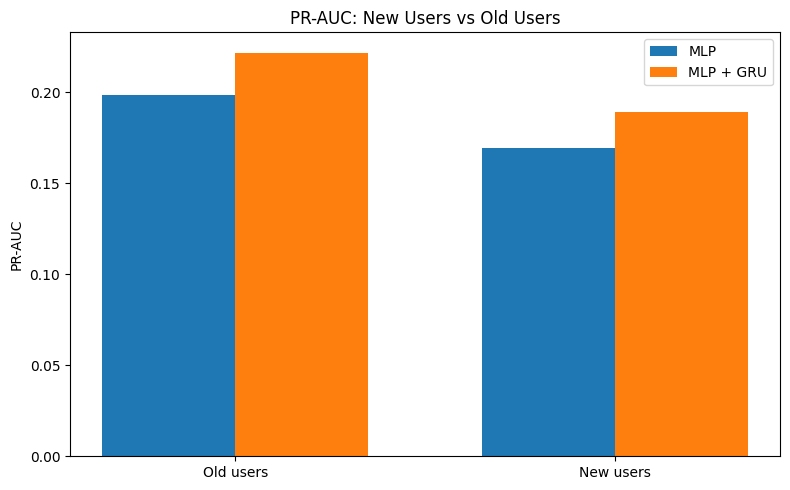

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# فقط دو گروه اصلی کاربران
main_groups = ['Old users', 'New users']

mlp_values = []
gru_values = []

for group_name in main_groups:

    group_data = results_df[
        results_df['Group'] == group_name
    ].set_index('Model')

    mlp_values.append(
        group_data.loc['MLP', 'PR-AUC']
    )

    gru_values.append(
        group_data.loc['MLP + GRU', 'PR-AUC']
    )


x = np.arange(len(main_groups))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    mlp_values,
    width,
    label='MLP'
)

plt.bar(
    x + width / 2,
    gru_values,
    width,
    label='MLP + GRU'
)

plt.xticks(x, main_groups)
plt.ylabel('PR-AUC')
plt.title('PR-AUC: New Users vs Old Users')
plt.legend()

plt.tight_layout()
plt.show()


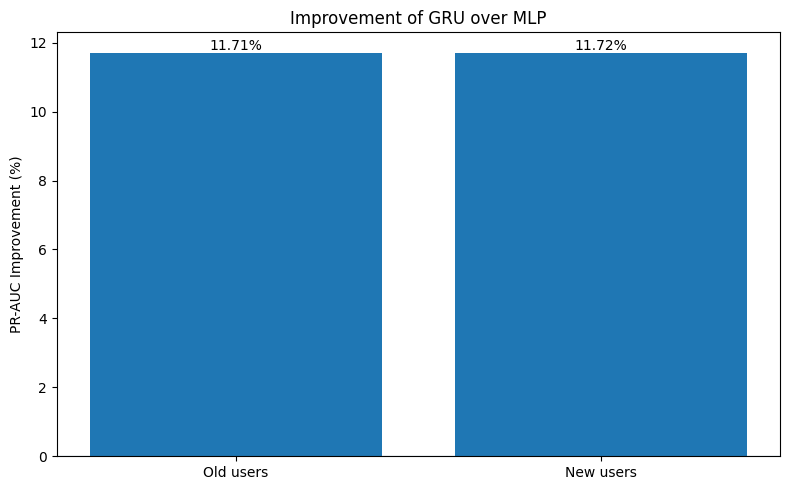

In [ ]:

plot_data = improvement_df[
    improvement_df['Group'].isin(main_groups)
]

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data['Group'],
    plot_data['PR-AUC Improvement (%)']
)

plt.axhline(0, linewidth=0.8)

plt.ylabel('PR-AUC Improvement (%)')
plt.title('Improvement of GRU over MLP')

for i, value in enumerate(
    plot_data['PR-AUC Improvement (%)']
):

    plt.text(
        i,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom' if value >= 0 else 'top'
    )

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
from sklearn.metrics import average_precision_score

# کاربران مجموعه Validation
val_users = user_ids_all[n_train:]

unique_users, user_codes = np.unique(
    val_users, return_inverse=True
)

# نتایج واقعی
mlp_ap = average_precision_score(y_eval, mlp_probs)
gru_ap = average_precision_score(y_eval, gru_probs)

# Bootstrap
N_BOOT = 300
rng = np.random.default_rng(42)

differences = []
relative_gains = []

for _ in range(N_BOOT):

    # نمونه‌گیری کاربران با جایگزینی
    sampled = rng.integers(
        0, len(unique_users), len(unique_users)
    )

    # وزن هر کاربر در نمونه Bootstrap
    user_weights = np.bincount(
        sampled, minlength=len(unique_users)
    )

    row_weights = user_weights[user_codes]

    # PR-AUC دو مدل روی نمونه یکسان
    ap_mlp = average_precision_score(
        y_eval, mlp_probs, sample_weight=row_weights
    )

    ap_gru = average_precision_score(
        y_eval, gru_probs, sample_weight=row_weights
    )

    differences.append(ap_gru - ap_mlp)

    relative_gains.append(
        (ap_gru - ap_mlp) / ap_mlp * 100
    )

# فاصله اطمینان 95 درصد
ci_diff = np.percentile(differences, [2.5, 97.5])
ci_relative = np.percentile(relative_gains, [2.5, 97.5])

print(f"MLP PR-AUC: {mlp_ap:.5f}")
print(f"GRU PR-AUC: {gru_ap:.5f}")

print(f"\nPR-AUC Difference: {gru_ap - mlp_ap:.5f}")
print(f"95% CI: [{ci_diff[0]:.5f}, {ci_diff[1]:.5f}]")

print(f"\nRelative Improvement: {(gru_ap/mlp_ap - 1)*100:.2f}%")
print(f"95% CI: [{ci_relative[0]:.2f}%, {ci_relative[1]:.2f}%]")

if ci_diff[0] > 0:
    print("\nThe improvement is statistically supported by the bootstrap CI.")
else:
    print("\nThe CI includes zero; improvement is not conclusive.")


MLP PR-AUC: 0.19070
GRU PR-AUC: 0.21187

PR-AUC Difference: 0.02117
95% CI: [0.01919, 0.02297]

Relative Improvement: 11.10%
95% CI: [10.06%, 12.05%]

The improvement is statistically supported by the bootstrap CI.


In [ ]:

# اصلاح تابع محاسبه PR-AUC وزن‌دار
def fast_weighted_ap(sorted_codes, sorted_y, starts, user_weights):

    row_weights = user_weights[sorted_codes]

    positive_weights = row_weights * sorted_y

    tp = np.add.reduceat(positive_weights, starts)
    total = np.add.reduceat(row_weights, starts)

    total_positive = tp.sum()

    if total_positive <= 0:
        return np.nan

    cumulative_tp = np.cumsum(tp)
    cumulative_total = np.cumsum(total)

    # جلوگیری از تقسیم صفر بر صفر
    precision = np.divide(
        cumulative_tp,
        cumulative_total,
        out=np.zeros_like(cumulative_tp, dtype=np.float64),
        where=cumulative_total > 0
    )

    return np.sum(
        (tp / total_positive) * precision
    )


# --------------------------------
# Bootstrap با 2000 نمونه معتبر
# --------------------------------

N_BOOT = 2000
rng = np.random.default_rng(42)

differences = []
relative_gains = []

attempts = 0
max_attempts = N_BOOT * 5

while len(differences) < N_BOOT and attempts < max_attempts:

    attempts += 1

    sampled_users = rng.integers(
        0,
        len(unique_users),
        size=len(unique_users)
    )

    user_weights = np.bincount(
        sampled_users,
        minlength=len(unique_users)
    )

    ap_mlp = fast_weighted_ap(
        *mlp_cache, user_weights
    )

    ap_gru = fast_weighted_ap(
        *gru_cache, user_weights
    )

    if not np.isfinite(ap_mlp) or not np.isfinite(ap_gru):
        continue

    differences.append(ap_gru - ap_mlp)

    relative_gains.append(
        (ap_gru - ap_mlp) / ap_mlp * 100
    )

    if len(differences) % 200 == 0:
        print(f"Valid bootstrap samples: {len(differences)}/{N_BOOT}")


assert len(differences) == N_BOOT, (
    "Could not obtain 2000 valid bootstrap samples."
)

# --------------------------------
# فاصله اطمینان 95 درصد
# --------------------------------

ci_diff = np.percentile(
    differences, [2.5, 97.5]
)

ci_relative = np.percentile(
    relative_gains, [2.5, 97.5]
)

print("\n========== FINAL RESULTS ==========")

print("Valid bootstrap samples:", len(differences))

print(f"MLP PR-AUC: {mlp_check:.5f}")
print(f"GRU PR-AUC: {gru_check:.5f}")

print(f"\nPR-AUC Difference: {gru_check - mlp_check:.5f}")
print(f"95% CI: [{ci_diff[0]:.5f}, {ci_diff[1]:.5f}]")

print(f"\nRelative Improvement: {(gru_check/mlp_check - 1)*100:.2f}%")
print(f"95% CI: [{ci_relative[0]:.2f}%, {ci_relative[1]:.2f}%]")

print(
    "Bootstrap samples with non-positive improvement:",
    np.sum(np.array(differences) <= 0)
)


Valid bootstrap samples: 200/2000
Valid bootstrap samples: 400/2000
Valid bootstrap samples: 600/2000
Valid bootstrap samples: 800/2000
Valid bootstrap samples: 1000/2000
Valid bootstrap samples: 1200/2000
Valid bootstrap samples: 1400/2000
Valid bootstrap samples: 1600/2000
Valid bootstrap samples: 1800/2000
Valid bootstrap samples: 2000/2000

========== FINAL RESULTS ==========
Valid bootstrap samples: 2000
MLP PR-AUC: 0.19070
GRU PR-AUC: 0.21187

PR-AUC Difference: 0.02117
95% CI: [0.01925, 0.02302]

Relative Improvement: 11.10%
95% CI: [10.07%, 12.12%]
Bootstrap samples with non-positive improvement: 0


fanal test

In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import gc

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# تعداد داده‌های توسعه و Final Test
n_dev = len(X_cat_all)
n_later = len(later_data)
SEQ_LEN = 10

assert len(X_num_all) == n_dev
assert len(user_ids_all) == n_dev
assert len(event_time_ns) == n_dev

# ویژگی‌های دسته‌ای Final Test
X_cat_later = np.column_stack([
    later_data[col].cat.codes.to_numpy(dtype=np.int32)
    for col in categorical_cols
])

# بررسی کدهای دسته‌ای
for i, col in enumerate(categorical_cols):
    assert X_cat_later[:, i].min() >= 0
    assert X_cat_later[:, i].max() < embedding_sizes[col]

# ویژگی‌های عددی Final Test
X_num_later = later_data[numeric_cols].to_numpy(
    dtype=np.float32,
    copy=True
)

# استفاده از میانگین و انحراف معیار Train قبلی
for col in continuous_cols:
    i = numeric_cols.index(col)

    X_num_later[:, i] = (
        X_num_later[:, i] - num_means[col]
    ) / num_stds[col]

# برچسب واقعی فقط برای ارزیابی نهایی
y_later = later_data['is_booking'].to_numpy(
    dtype=np.float32
)

# کاربران و زمان‌های Final Test
users_later = later_data['user'].to_numpy(
    dtype=np.int64
)

times_later = later_data['search_date'].to_numpy(
    dtype='datetime64[ns]'
).astype(np.int64)

assert np.isfinite(X_num_later).all()
assert len(y_later) == n_later

# ترکیب ویژگی‌های توسعه و آزمون
X_cat_final = np.concatenate(
    [X_cat_all, X_cat_later], axis=0
)

X_num_final = np.concatenate(
    [X_num_all, X_num_later], axis=0
)

users_final = np.concatenate(
    [user_ids_all, users_later]
)

times_final = np.concatenate(
    [event_time_ns, times_later]
)

N_FINAL = len(users_final)

print("Development rows:", n_dev)
print("Final Test rows:", n_later)
print("Combined rows:", N_FINAL)
print("Final Test booking rate:", y_later.mean())


Development rows: 6952000
Final Test rows: 671000
Combined rows: 7623000
Final Test booking rate: 0.08866021


In [ ]:

# تعداد کل ردیف‌ها
history_indices_test = np.full(
    (n_later, SEQ_LEN),
    -1,
    dtype=np.int32
)

history_lengths_test = np.zeros(
    n_later,
    dtype=np.int8
)

# مرتب‌سازی همه تعاملات بر اساس کاربر و زمان
order = np.lexsort((times_final, users_final))

sorted_users = users_final[order]
sorted_times = times_final[order]

positions = np.arange(N_FINAL, dtype=np.int64)

# شروع هر کاربر
new_user = np.empty(N_FINAL, dtype=bool)
new_user[0] = True
new_user[1:] = (
    sorted_users[1:] != sorted_users[:-1]
)

user_start = np.maximum.accumulate(
    np.where(new_user, positions, 0)
)

# شروع هر بلوک زمانی برای هر کاربر
new_block = new_user.copy()
new_block[1:] |= (
    sorted_times[1:] != sorted_times[:-1]
)

block_start = np.maximum.accumulate(
    np.where(new_block, positions, 0)
)

# پیدا کردن موقعیت ردیف‌های Final Test در ترتیب مرتب‌شده
test_sorted_positions = np.flatnonzero(
    order >= n_dev
)

test_global_indices = order[test_sorted_positions]
test_local_indices = test_global_indices - n_dev

# تعداد تعاملات قبلی با زمان دقیقاً کوچک‌تر
available_history = (
    block_start[test_sorted_positions]
    - user_start[test_sorted_positions]
)

test_lengths_sorted = np.minimum(
    available_history, SEQ_LEN
).astype(np.int8)

history_lengths_test[test_local_indices] = (
    test_lengths_sorted
)

# ساخت 10 تعامل قبلی، از قدیمی به جدید
for slot in range(SEQ_LEN):

    mask = test_lengths_sorted > slot

    selected_positions = (
        test_sorted_positions[mask]
    )

    local_rows = test_local_indices[mask]

    source_positions = (
        block_start[selected_positions]
        - test_lengths_sorted[mask]
        + slot
    )

    history_indices_test[local_rows, slot] = (
        order[source_positions].astype(np.int32)
    )

# بررسی ترتیب زمانی روی نمونه‌ای از تاریخچه‌ها
sample_rows = np.flatnonzero(
    history_lengths_test > 0
)[:1000]

for row in sample_rows:

    idx = history_indices_test[row]
    idx = idx[idx >= 0]

    assert np.all(
        times_final[idx] < times_final[n_dev + row]
    )

print("Final history construction completed.")
print("History matrix:", history_indices_test.shape)
print("Requests without history:",
      (history_lengths_test == 0).sum())
print("Requests with history:",
      (history_lengths_test > 0).sum())

# آزادسازی حافظه موقت
del order, sorted_users, sorted_times, positions
del new_user, new_block, user_start, block_start
del test_sorted_positions, test_global_indices
del test_local_indices, available_history
del test_lengths_sorted, selected_positions
del source_positions, local_rows

gc.collect()

print("\nHistory time-order check passed.")


Final history construction completed.
History matrix: (671000, 10)
Requests without history: 69301
Requests with history: 601699

History time-order check passed.


In [ ]:

# آمار فاصله زمانی از مرحله آموزش
assert 'gap_mean' in globals()
assert 'gap_std' in globals()

def final_test_collate(batch):

    # شماره ردیف‌های محلی Final Test
    local_idx = np.array(
        [item[0].item() for item in batch],
        dtype=np.int64
    )

    # شماره جهانی ردیف‌ها
    global_idx = n_dev + local_idx

    # تاریخچه
    hist_idx = history_indices_test[local_idx]
    mask = hist_idx >= 0

    safe_idx = np.maximum(hist_idx, 0)

    # ویژگی‌های جست‌وجوی فعلی
    current_cat = X_cat_final[global_idx].copy()
    current_num = X_num_final[global_idx].copy()

    # ویژگی‌های تاریخی
    hist_cat = X_cat_final[safe_idx].copy()
    hist_num = X_num_final[safe_idx].copy()

    hist_cat[~mask] = 0
    hist_num[~mask] = 0

    # فاصله زمانی تا تعامل فعلی
    delta_ns = (
        times_final[global_idx][:, None]
        - times_final[safe_idx]
    )

    delta_hours = np.maximum(
        delta_ns / 3_600_000_000_000,
        0
    )

    gap = np.log1p(delta_hours).astype(np.float32)

    gap = (
        gap - np.float32(gap_mean)
    ) / np.float32(gap_std)

    gap[~mask] = 0

    lengths = history_lengths_test[
        local_idx
    ].astype(np.int64)

    return (
        torch.from_numpy(current_cat),
        torch.from_numpy(current_num),
        torch.from_numpy(hist_cat),
        torch.from_numpy(hist_num),
        torch.from_numpy(gap),
        torch.from_numpy(lengths)
    )


# DataLoader آزمون
final_dataset = TensorDataset(
    torch.arange(n_later, dtype=torch.long)
)

final_loader = DataLoader(
    final_dataset,
    batch_size=1024,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=final_test_collate
)

print("Final Test batches:", len(final_loader))


# --------------------------------
# بارگذاری بهترین وزن‌های ذخیره‌شده
# --------------------------------

import os

if os.path.exists('best_booking_mlp.pt'):
    model.load_state_dict(
        torch.load(
            'best_booking_mlp.pt',
            map_location='cpu',
            weights_only=True
        )
    )

if os.path.exists('best_booking_gru.pt'):
    model_gru.load_state_dict(
        torch.load(
            'best_booking_gru.pt',
            map_location='cpu',
            weights_only=True
        )
    )

# انتقال مدل‌ها به GPU
device = torch.device('cuda')

model = model.to(device).eval()
model_gru = model_gru.to(device).eval()


# وزن کلاس مثبت، فقط از Train
positive_weight = float(pos_weight_gru)

print("Positive class weight:", positive_weight)


# --------------------------------
# پیش‌بینی MLP
# --------------------------------

mlp_test_logits = []

with torch.no_grad():

    for start in range(0, n_later, 8192):

        end = min(start + 8192, n_later)

        cat = torch.from_numpy(
            X_cat_later[start:end]
        ).to(device, dtype=torch.long)

        num = torch.from_numpy(
            X_num_later[start:end]
        ).to(device)

        logits = model(cat, num)

        mlp_test_logits.append(
            logits.squeeze(1).cpu().numpy()
        )

mlp_test_logits = np.concatenate(mlp_test_logits)

print("MLP predictions completed:", len(mlp_test_logits))


# --------------------------------
# پیش‌بینی MLP + GRU
# --------------------------------

gru_test_logits = []

with torch.no_grad():

    for batch_number, batch in enumerate(final_loader):

        (
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths
        ) = batch

        x_cat = x_cat.to(
            device, dtype=torch.long, non_blocking=True
        )
        x_num = x_num.to(device, non_blocking=True)

        hist_cat = hist_cat.to(
            device, dtype=torch.long, non_blocking=True
        )
        hist_num = hist_num.to(device, non_blocking=True)
        hist_gap = hist_gap.to(device, non_blocking=True)

        lengths = lengths.to(device)

        logits = model_gru(
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths
        )

        gru_test_logits.append(
            logits.squeeze(1).cpu().numpy()
        )

        if (batch_number + 1) % 100 == 0:
            print(
                f"GRU Test Batch: "
                f"{batch_number + 1}/{len(final_loader)}"
            )

gru_test_logits = np.concatenate(gru_test_logits)

print("\nGRU predictions completed:", len(gru_test_logits))

assert len(mlp_test_logits) == n_later
assert len(gru_test_logits) == n_later

print("\nBoth models have generated all Final Test predictions.")


Final Test batches: 656
Positive class weight: 10.308060646057129
MLP predictions completed: 671000
GRU Test Batch: 100/656
GRU Test Batch: 200/656
GRU Test Batch: 300/656
GRU Test Batch: 400/656
GRU Test Batch: 500/656
GRU Test Batch: 600/656

GRU predictions completed: 671000

Both models have generated all Final Test predictions.


FINAL TEST RESULTS
Test samples: 671000
Booking rate: 0.08866


,MLP,MLP + GRU
PR-AUC,0.20850,0.24041
ROC-AUC,0.75190,0.76747
Log Loss,0.26696,0.26103
Brier Score,0.07602,0.07461



Relative Improvement of GRU:


,Improvement (%)
PR-AUC,15.304
ROC-AUC,2.071
Log Loss,2.220
Brier Score,1.843


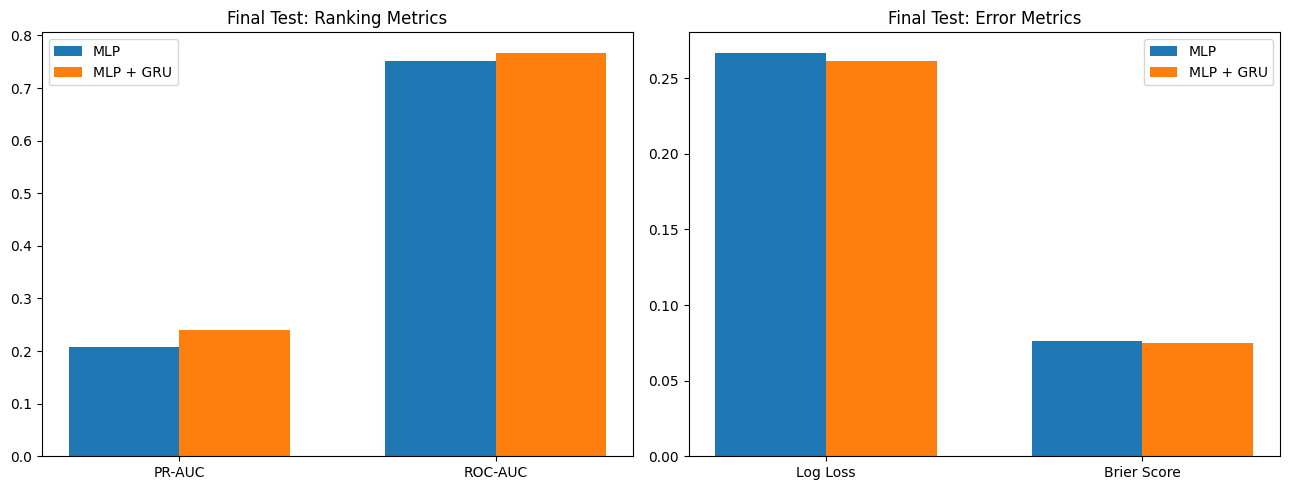

In [ ]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# اصلاح اثر pos_weight
mlp_test_probs = 1 / (
    1 + np.exp(-np.clip(
        mlp_test_logits - np.log(positive_weight),
        -50, 50
    ))
)

gru_test_probs = 1 / (
    1 + np.exp(-np.clip(
        gru_test_logits - np.log(positive_weight),
        -50, 50
    ))
)


# تابع ارزیابی
def evaluate_model(y_true, probabilities):

    probabilities = np.clip(
        probabilities, 1e-7, 1 - 1e-7
    )

    return {
        'PR-AUC': average_precision_score(
            y_true, probabilities
        ),
        'ROC-AUC': roc_auc_score(
            y_true, probabilities
        ),
        'Log Loss': log_loss(
            y_true, probabilities,
            labels=[0, 1]
        ),
        'Brier Score': brier_score_loss(
            y_true, probabilities
        )
    }


# ارزیابی هر دو مدل
mlp_test_results = evaluate_model(
    y_later, mlp_test_probs
)

gru_test_results = evaluate_model(
    y_later, gru_test_probs
)

# جدول مقایسه
final_comparison = pd.DataFrame({
    'MLP': mlp_test_results,
    'MLP + GRU': gru_test_results
})

print("FINAL TEST RESULTS")
print("Test samples:", len(y_later))
print("Booking rate:", round(y_later.mean(), 5))

display(final_comparison.round(5))


# محاسبه درصد بهبود
higher_is_better = ['PR-AUC', 'ROC-AUC']

improvements = {}

for metric in final_comparison.index:

    mlp_value = final_comparison.loc[metric, 'MLP']
    gru_value = final_comparison.loc[metric, 'MLP + GRU']

    if metric in higher_is_better:
        improvement = (
            (gru_value - mlp_value) / mlp_value
        ) * 100
    else:
        improvement = (
            (mlp_value - gru_value) / mlp_value
        ) * 100

    improvements[metric] = improvement

improvement_table = pd.DataFrame({
    'Improvement (%)': improvements
})

print("\nRelative Improvement of GRU:")
display(improvement_table.round(3))


# --------------------------------
# نمودار مقایسه معیارها
# --------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# نمودار PR-AUC و ROC-AUC
ranking_metrics = ['PR-AUC', 'ROC-AUC']

x = np.arange(len(ranking_metrics))
width = 0.35

axes[0].bar(
    x - width / 2,
    [mlp_test_results[m] for m in ranking_metrics],
    width,
    label='MLP'
)

axes[0].bar(
    x + width / 2,
    [gru_test_results[m] for m in ranking_metrics],
    width,
    label='MLP + GRU'
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(ranking_metrics)
axes[0].set_title('Final Test: Ranking Metrics')
axes[0].legend()

# نمودار خطاها
error_metrics = ['Log Loss', 'Brier Score']

x2 = np.arange(len(error_metrics))

axes[1].bar(
    x2 - width / 2,
    [mlp_test_results[m] for m in error_metrics],
    width,
    label='MLP'
)

axes[1].bar(
    x2 + width / 2,
    [gru_test_results[m] for m in error_metrics],
    width,
    label='MLP + GRU'
)

axes[1].set_xticks(x2)
axes[1].set_xticklabels(error_metrics)
axes[1].set_title('Final Test: Error Metrics')
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
from sklearn.metrics import average_precision_score

# کاربران Final Test
unique_test_users, test_user_codes = np.unique(
    users_later,
    return_inverse=True
)

# آماده‌سازی سریع PR-AUC
def prepare_test_ap(y, scores, codes):

    order = np.argsort(-scores, kind='mergesort')
    sorted_scores = scores[order]

    starts = np.r_[
        0,
        np.flatnonzero(
            sorted_scores[1:] != sorted_scores[:-1]
        ) + 1
    ]

    return (
        codes[order],
        y[order].astype(np.float64),
        starts
    )


def weighted_ap(cache, user_weights):

    codes, labels, starts = cache

    row_weights = user_weights[codes]

    tp = np.add.reduceat(
        row_weights * labels, starts
    )

    total = np.add.reduceat(
        row_weights, starts
    )

    total_positive = tp.sum()

    if total_positive <= 0:
        return np.nan

    precision = np.divide(
        np.cumsum(tp),
        np.cumsum(total),
        out=np.zeros(len(tp), dtype=np.float64),
        where=np.cumsum(total) > 0
    )

    return np.sum(
        (tp / total_positive) * precision
    )


mlp_cache_test = prepare_test_ap(
    y_later, mlp_test_probs, test_user_codes
)

gru_cache_test = prepare_test_ap(
    y_later, gru_test_probs, test_user_codes
)

# Bootstrap
N_BOOT = 2000
rng = np.random.default_rng(42)

differences = []
relative_gains = []

n_users = len(unique_test_users)

while len(differences) < N_BOOT:

    sampled = rng.integers(
        0, n_users, size=n_users
    )

    weights = np.bincount(
        sampled, minlength=n_users
    )

    ap_mlp = weighted_ap(mlp_cache_test, weights)
    ap_gru = weighted_ap(gru_cache_test, weights)

    if not np.isfinite(ap_mlp) or not np.isfinite(ap_gru):
        continue

    differences.append(ap_gru - ap_mlp)

    relative_gains.append(
        (ap_gru / ap_mlp - 1) * 100
    )

    if len(differences) % 200 == 0:
        print(f"Bootstrap: {len(differences)}/{N_BOOT}")


# فاصله اطمینان 95 درصد
ci_difference = np.percentile(
    differences, [2.5, 97.5]
)

ci_gain = np.percentile(
    relative_gains, [2.5, 97.5]
)

print("\nFINAL TEST BOOTSTRAP")
print("MLP PR-AUC:", average_precision_score(y_later, mlp_test_probs))
print("GRU PR-AUC:", average_precision_score(y_later, gru_test_probs))

print("PR-AUC Difference:",
      np.mean(differences))

print("95% CI Difference:",
      ci_difference)

print("Relative Improvement (%):",
      (average_precision_score(y_later, gru_test_probs) /
       average_precision_score(y_later, mlp_test_probs) - 1) * 100)

print("95% CI Relative Improvement:",
      ci_gain)

print("Non-positive improvements:",
      np.sum(np.array(differences) <= 0))


Bootstrap: 200/2000
Bootstrap: 400/2000
Bootstrap: 600/2000
Bootstrap: 800/2000
Bootstrap: 1000/2000
Bootstrap: 1200/2000
Bootstrap: 1400/2000
Bootstrap: 1600/2000
Bootstrap: 1800/2000
Bootstrap: 2000/2000

FINAL TEST BOOTSTRAP
MLP PR-AUC: 0.2084984265141864
GRU PR-AUC: 0.24040803959944096
PR-AUC Difference: 0.03193619994676187
95% CI Difference: [0.02952442 0.03426348]
Relative Improvement (%): 15.304486282577967
95% CI Relative Improvement: [14.10410838 16.52339073]
Non-positive improvements: 0


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# نتایج Final Test
mlp_results = {
    'PR-AUC': 0.2084984265,
    'ROC-AUC': 0.75190,
    'Log Loss': 0.26696,
    'Brier Score': 0.07602
}

gru_results = {
    'PR-AUC': 0.2404080396,
    'ROC-AUC': 0.76747,
    'Log Loss': 0.26103,
    'Brier Score': 0.07461
}

higher_is_better = ['PR-AUC', 'ROC-AUC']

rows = []

for metric in mlp_results:

    m1 = mlp_results[metric]
    m2 = gru_results[metric]

    if metric in higher_is_better:
        improvement = (m2 - m1) / m1 * 100
    else:
        improvement = (m1 - m2) / m1 * 100

    rows.append({
        'Metric': metric,
        'MLP': m1,
        'MLP + GRU': m2,
        'Improvement (%)': improvement
    })

final_results_table = pd.DataFrame(rows)

print("Independent Test: Model Comparison")
display(final_results_table.round(5))


Independent Test: Model Comparison


,Metric,MLP,MLP + GRU,Improvement (%)
0,PR-AUC,0.20850,0.24041,15.30449
1,ROC-AUC,0.75190,0.76747,2.07075
2,Log Loss,0.26696,0.26103,2.22131
3,Brier Score,0.07602,0.07461,1.85478


In [ ]:

# فاصله اطمینان 95 درصد
ci_difference = np.percentile(
    differences, [2.5, 97.5]
)

ci_relative = np.percentile(
    relative_gains, [2.5, 97.5]
)

# اختلاف واقعی دو مدل
observed_difference = (
    mlp_results['PR-AUC'] * 0 +
    gru_results['PR-AUC'] -
    mlp_results['PR-AUC']
)

observed_improvement = (
    observed_difference / mlp_results['PR-AUC'] * 100
)

bootstrap_table = pd.DataFrame({
    'Measure': [
        'Absolute PR-AUC Difference',
        'Relative PR-AUC Improvement'
    ],
    'Observed Value': [
        observed_difference,
        observed_improvement
    ],
    'CI Lower (95%)': [
        ci_difference[0],
        ci_relative[0]
    ],
    'CI Upper (95%)': [
        ci_difference[1],
        ci_relative[1]
    ]
})

print("User-level Bootstrap Results (2000 Resamples)")
display(bootstrap_table.round(5))

print("Non-positive improvements:",
      np.sum(np.array(differences) <= 0))


User-level Bootstrap Results (2000 Resamples)


,Measure,Observed Value,CI Lower (95%),CI Upper (95%)
0,Absolute PR-AUC Difference,0.03191,0.02952,0.03426
1,Relative PR-AUC Improvement,15.30449,14.10411,16.52339


Non-positive improvements: 0


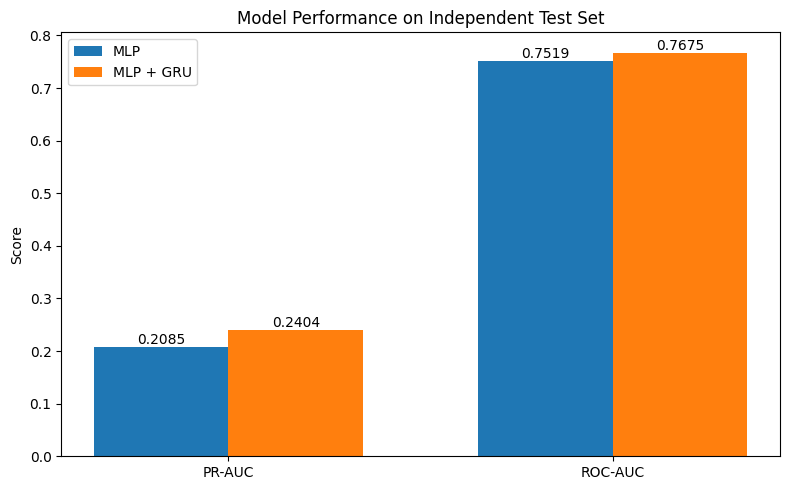

In [ ]:

metrics = ['PR-AUC', 'ROC-AUC']

mlp_values = [mlp_results[m] for m in metrics]
gru_values = [gru_results[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    mlp_values,
    width,
    label='MLP'
)

bars2 = plt.bar(
    x + width/2,
    gru_values,
    width,
    label='MLP + GRU'
)

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.title('Model Performance on Independent Test Set')
plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{bar.get_height():.4f}',
            ha='center'
        )

plt.tight_layout()
plt.savefig('final_test_ranking_metrics.png', dpi=300)
plt.show()


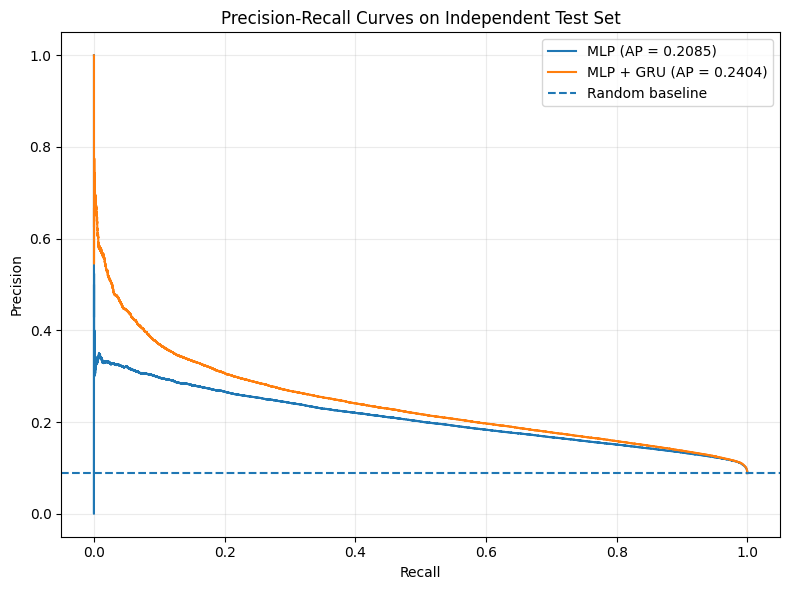

In [ ]:

from sklearn.metrics import precision_recall_curve

precision_mlp, recall_mlp, _ = precision_recall_curve(
    y_later, mlp_test_probs
)

precision_gru, recall_gru, _ = precision_recall_curve(
    y_later, gru_test_probs
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_mlp,
    precision_mlp,
    label=f'MLP (AP = {mlp_results["PR-AUC"]:.4f})'
)

plt.plot(
    recall_gru,
    precision_gru,
    label=f'MLP + GRU (AP = {gru_results["PR-AUC"]:.4f})'
)

plt.axhline(
    y=y_later.mean(),
    linestyle='--',
    label='Random baseline'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves on Independent Test Set')

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig('final_test_precision_recall.png', dpi=300)
plt.show()


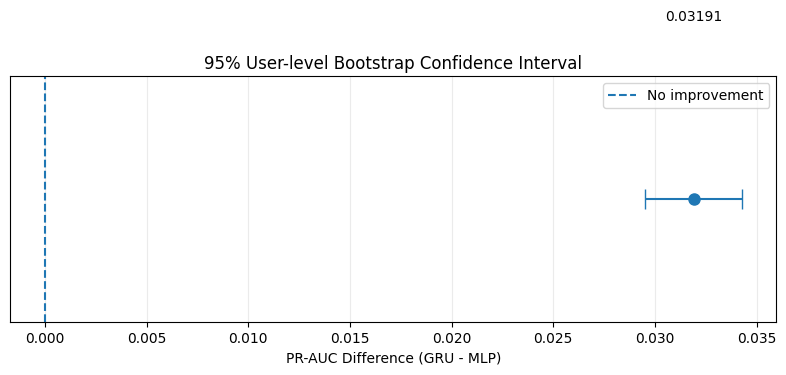

In [ ]:

plt.figure(figsize=(8, 4))

point = observed_difference

lower = ci_difference[0]
upper = ci_difference[1]

plt.errorbar(
    point,
    0,
    xerr=[[point - lower], [upper - point]],
    fmt='o',
    capsize=7,
    markersize=8
)

plt.axvline(
    0,
    linestyle='--',
    label='No improvement'
)

plt.xlabel('PR-AUC Difference (GRU - MLP)')
plt.yticks([])
plt.title('95% User-level Bootstrap Confidence Interval')

plt.text(
    point,
    0.08,
    f'{point:.5f}',
    ha='center'
)

plt.legend()
plt.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.savefig('final_test_bootstrap_ci.png', dpi=300)
plt.show()


In [ ]:
final_results_table.to_csv(
    'final_test_comparison.csv',
    index=False
)

bootstrap_table.to_csv(
    'final_test_bootstrap.csv',
    index=False
)

In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# تثبیت Seed
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)

device = torch.device('cuda')


# آزاد کردن حافظه GPU مدل‌های قبلی
model = model.cpu()
model_gru = model_gru.cpu()
torch.cuda.empty_cache()


# مدل GRU بدون Time Gap
class BookingHistoryGRU_NoGap(nn.Module):

    def __init__(self, baseline_model, num_numeric, hidden_size=128):

        super().__init__()

        self.embeddings = copy.deepcopy(
            baseline_model.embeddings
        )

        self.current_branch = copy.deepcopy(
            nn.Sequential(
                *list(baseline_model.mlp.children())[:-1]
            )
        )

        embedding_dim = sum(
            layer.embedding_dim
            for layer in self.embeddings
        )

        # بدون ویژگی فاصله زمانی
        self.gru = nn.GRU(
            input_size=embedding_dim + num_numeric,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fusion = nn.Sequential(
            nn.Linear(64 + hidden_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(
        self, x_cat, x_num,
        hist_cat, hist_num,
        hist_gap, lengths
    ):

        # شاخه اطلاعات فعلی
        current_emb = torch.cat([
            emb(x_cat[:, i].long())
            for i, emb in enumerate(self.embeddings)
        ], dim=1)

        current_input = torch.cat(
            [current_emb, x_num], dim=1
        )

        current_output = self.current_branch(
            current_input
        )

        # شاخه تاریخچه بدون Time Gap
        hist_emb = torch.cat([
            emb(hist_cat[:, :, i].long())
            for i, emb in enumerate(self.embeddings)
        ], dim=2)

        history_input = torch.cat(
            [hist_emb, hist_num], dim=2
        )

        positions = torch.arange(
            hist_cat.size(1),
            device=lengths.device
        ).unsqueeze(0)

        mask = positions < lengths.unsqueeze(1)

        history_input = (
            history_input * mask.unsqueeze(-1)
        )

        safe_lengths = lengths.clamp(min=1).cpu()

        packed = pack_padded_sequence(
            history_input,
            safe_lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        history_output = hidden[-1]

        has_history = (
            lengths > 0
        ).to(history_output.dtype).unsqueeze(1)

        history_output = history_output * has_history

        # ترکیب دو شاخه
        combined = torch.cat(
            [current_output, history_output],
            dim=1
        )

        return self.fusion(combined)


# ساخت مدل از وزن‌های MLP قبلی
model_no_gap = BookingHistoryGRU_NoGap(
    baseline_model=model,
    num_numeric=len(numeric_cols),
    hidden_size=128
).to(device)

print(model_no_gap)
print(
    "\nParameters:",
    sum(p.numel() for p in model_no_gap.parameters())
)


BookingHistoryGRU_NoGap(
  (embeddings): ModuleList(
    (0): Embedding(235, 50)
    (1): Embedding(964, 50)
    (2): Embedding(36891, 50)
    (3): Embedding(12, 6)
    (4): Embedding(38888, 50)
    (5): Embedding(10, 5)
    (6): Embedding(8, 4)
    (7): Embedding(212, 50)
    (8): Embedding(2113, 50)
    (9): Embedding(101, 50)
    (10): Embedding(25, 13)
    (11): Embedding(8, 4)
  )
  (current_branch): Sequential(
    (0): Linear(in_features=396, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.1, inplace=False)
  )
  (gru): GRU(396, 128,

In [ ]:

# تابع خطا
pos_weight_ablation = float(pos_weight_gru)

criterion_ablation = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight_ablation],
        device=device
    )
)

# بهینه‌ساز
optimizer_ablation = torch.optim.AdamW(
    [
        {
            'params': list(model_no_gap.embeddings.parameters())
                      + list(model_no_gap.current_branch.parameters()),
            'lr': 0.0001
        },
        {
            'params': list(model_no_gap.gru.parameters())
                      + list(model_no_gap.fusion.parameters()),
            'lr': 0.0003
        }
    ],
    weight_decay=1e-5
)

EPOCHS = 5
PATIENCE = 2

best_ap_no_gap = -1
wait = 0
y_val = y_all[n_train:].reshape(-1)

best_state_no_gap = None
best_logits_no_gap = None

for epoch in range(EPOCHS):

    model_no_gap.train()
    total_loss = 0

    # ---------------- Training ----------------
    for step, batch in enumerate(train_gru_loader):

        x_cat, x_num, hist_cat, hist_num, hist_gap, lengths, y = batch

        x_cat = x_cat.to(device, dtype=torch.long)
        x_num = x_num.to(device)
        hist_cat = hist_cat.to(device, dtype=torch.long)
        hist_num = hist_num.to(device)
        hist_gap = hist_gap.to(device)
        lengths = lengths.to(device)
        y = y.to(device)

        optimizer_ablation.zero_grad(set_to_none=True)

        logits = model_no_gap(
            x_cat, x_num,
            hist_cat, hist_num,
            hist_gap, lengths
        )

        loss = criterion_ablation(logits, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_no_gap.parameters(), 1.0
        )

        optimizer_ablation.step()

        total_loss += loss.item() * len(y)

        if (step + 1) % 500 == 0:
            print(f"Epoch {epoch+1}: Batch {step+1}")

    train_loss = total_loss / n_train

    # ---------------- Validation ----------------
    model_no_gap.eval()

    valid_loss = 0
    logits_list = []

    with torch.no_grad():

        for batch in valid_gru_loader:

            x_cat, x_num, hist_cat, hist_num, hist_gap, lengths, y = batch

            x_cat = x_cat.to(device, dtype=torch.long)
            x_num = x_num.to(device)
            hist_cat = hist_cat.to(device, dtype=torch.long)
            hist_num = hist_num.to(device)
            hist_gap = hist_gap.to(device)
            lengths = lengths.to(device)
            y = y.to(device)

            logits = model_no_gap(
                x_cat, x_num,
                hist_cat, hist_num,
                hist_gap, lengths
            )

            loss = criterion_ablation(logits, y)

            valid_loss += loss.item() * len(y)

            logits_list.append(
                logits.squeeze(1).cpu().numpy()
            )

    valid_loss /= n_valid

    val_logits = np.concatenate(logits_list)

    # اصلاح اثر وزن کلاس مثبت
    corrected_logits = (
        val_logits - np.log(pos_weight_ablation)
    )

    val_probs = 1 / (
        1 + np.exp(-np.clip(corrected_logits, -50, 50))
    )

    pr_auc = average_precision_score(y_val, val_probs)
    roc_auc = roc_auc_score(y_val, val_probs)
    logloss = log_loss(y_val, val_probs, labels=[0, 1])
    brier = brier_score_loss(y_val, val_probs)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.5f}")
    print(f"Validation Loss: {valid_loss:.5f}")
    print(f"PR-AUC: {pr_auc:.5f}")
    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Log Loss: {logloss:.5f}")
    print(f"Brier Score: {brier:.5f}")

    if pr_auc > best_ap_no_gap:

        best_ap_no_gap = pr_auc
        best_logits_no_gap = val_logits.copy()

        best_state_no_gap = {
            k: v.detach().cpu().clone()
            for k, v in model_no_gap.state_dict().items()
        }

        torch.save(
            best_state_no_gap,
            'best_booking_gru_no_time.pt'
        )

        wait = 0
        print("Best no-time-gap model saved.")

    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping.")
        break


# بارگذاری بهترین مدل
model_no_gap.load_state_dict(
    torch.load(
        'best_booking_gru_no_time.pt',
        map_location=device,
        weights_only=True
    )
)

print("\nAblation training completed.")
print("Best PR-AUC:", best_ap_no_gap)


Epoch 1: Batch 500
Epoch 1: Batch 1000
Epoch 1: Batch 1500
Epoch 1: Batch 2000
Epoch 1: Batch 2500

Epoch 1/5
Train Loss: 0.95546
Validation Loss: 0.96908
PR-AUC: 0.19756
ROC-AUC: 0.76561
Log Loss: 0.23679
Brier Score: 0.06608
Best no-time-gap model saved.
Epoch 2: Batch 500
Epoch 2: Batch 1000
Epoch 2: Batch 1500
Epoch 2: Batch 2000
Epoch 2: Batch 2500

Epoch 2/5
Train Loss: 0.94102
Validation Loss: 0.96648
PR-AUC: 0.20058
ROC-AUC: 0.76735
Log Loss: 0.23634
Brier Score: 0.06601
Best no-time-gap model saved.
Epoch 3: Batch 500
Epoch 3: Batch 1000
Epoch 3: Batch 1500
Epoch 3: Batch 2000
Epoch 3: Batch 2500

Epoch 3/5
Train Loss: 0.93145
Validation Loss: 0.96749
PR-AUC: 0.20035
ROC-AUC: 0.76703
Log Loss: 0.23643
Brier Score: 0.06601
Epoch 4: Batch 500
Epoch 4: Batch 1000
Epoch 4: Batch 1500
Epoch 4: Batch 2000
Epoch 4: Batch 2500

Epoch 4/5
Train Loss: 0.92122
Validation Loss: 0.96979
PR-AUC: 0.20338
ROC-AUC: 0.76825
Log Loss: 0.23716
Brier Score: 0.06630
Best no-time-gap model saved.
Ep

Ablation Study Results:


,MLP,MLP + GRU (No Time Gap),MLP + GRU (Full)
PR-AUC,0.19070,0.20338,0.21187
ROC-AUC,0.75966,0.76825,0.77025
Log Loss,0.23959,0.23716,0.23508
Brier Score,0.06656,0.06630,0.06561


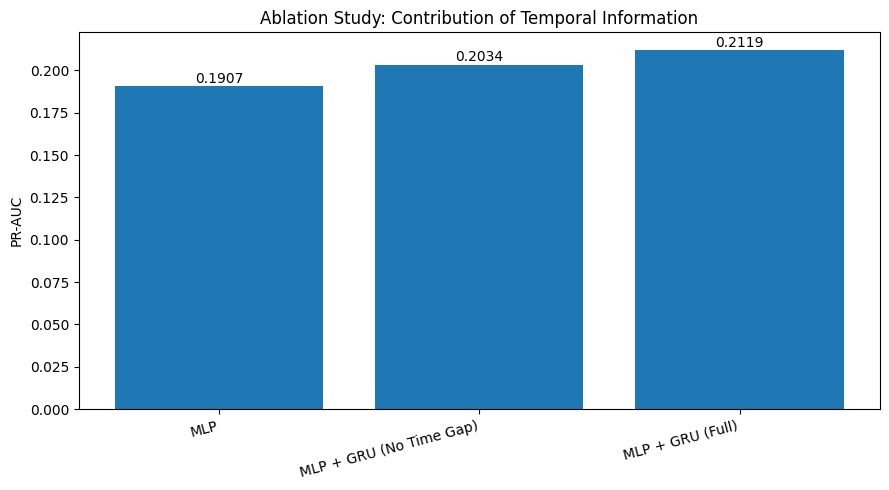

In [ ]:

# احتمال‌های بهترین مدل بدون Time Gap
no_gap_logits = best_logits_no_gap - np.log(pos_weight_ablation)

no_gap_probs = 1 / (
    1 + np.exp(-np.clip(no_gap_logits, -50, 50))
)

# نتایج سه مدل روی Validation
ablation_table = pd.DataFrame({
    'MLP': {
        'PR-AUC': 0.19070,
        'ROC-AUC': 0.75966,
        'Log Loss': 0.23959,
        'Brier Score': 0.06656
    },
    'MLP + GRU (No Time Gap)': {
        'PR-AUC': average_precision_score(y_val, no_gap_probs),
        'ROC-AUC': roc_auc_score(y_val, no_gap_probs),
        'Log Loss': log_loss(y_val, no_gap_probs),
        'Brier Score': brier_score_loss(y_val, no_gap_probs)
    },
    'MLP + GRU (Full)': {
        'PR-AUC': 0.211871,
        'ROC-AUC': 0.77025,
        'Log Loss': 0.23508,
        'Brier Score': 0.06561
    }
})

print("Ablation Study Results:")
display(ablation_table.round(5))


# نمودار PR-AUC
plt.figure(figsize=(9, 5))

plt.bar(
    ablation_table.columns,
    ablation_table.loc['PR-AUC'].values
)

plt.ylabel('PR-AUC')
plt.title('Ablation Study: Contribution of Temporal Information')
plt.xticks(rotation=15, ha='right')

for i, value in enumerate(
    ablation_table.loc['PR-AUC'].values
):
    plt.text(i, value + 0.002, f'{value:.4f}', ha='center')

plt.tight_layout()
plt.savefig('ablation_pr_auc.png', dpi=300)
plt.show()


In [ ]:

import numpy as np
from sklearn.metrics import average_precision_score

# خروجی دو مدل روی Validation
y_ab = y_all[n_train:].reshape(-1).astype(np.int8)

scores_full = np.asarray(
    best_valid_logits_gru
).reshape(-1)

scores_no_gap = np.asarray(
    best_logits_no_gap
).reshape(-1)

# شناسه کاربران Validation
val_users = user_ids_all[n_train:]

unique_users, user_codes = np.unique(
    val_users, return_inverse=True
)

# آماده‌سازی سریع PR-AUC
def prepare_ap(y, scores, codes):

    order = np.argsort(-scores, kind='mergesort')

    sorted_scores = scores[order]
    starts = np.r_[
        0,
        np.flatnonzero(
            sorted_scores[1:] != sorted_scores[:-1]
        ) + 1
    ]

    return codes[order], y[order].astype(float), starts


def weighted_ap(cache, weights):

    codes, labels, starts = cache

    row_weights = weights[codes]

    tp = np.add.reduceat(
        row_weights * labels, starts
    )

    total = np.add.reduceat(
        row_weights, starts
    )

    total_positive = tp.sum()

    if total_positive == 0:
        return np.nan

    cumulative_total = np.cumsum(total)

    precision = np.divide(
        np.cumsum(tp),
        cumulative_total,
        out=np.zeros_like(cumulative_total, dtype=float),
        where=cumulative_total > 0
    )

    return np.sum(
        (tp / total_positive) * precision
    )


full_cache = prepare_ap(
    y_ab, scores_full, user_codes
)

nogap_cache = prepare_ap(
    y_ab, scores_no_gap, user_codes
)

# کنترل محاسبه
ap_full = average_precision_score(y_ab, scores_full)
ap_no_gap = average_precision_score(y_ab, scores_no_gap)

assert np.isclose(
    weighted_ap(full_cache, np.ones(len(unique_users))),
    ap_full
)

assert np.isclose(
    weighted_ap(nogap_cache, np.ones(len(unique_users))),
    ap_no_gap
)

# Bootstrap
N_BOOT = 2000
rng = np.random.default_rng(42)

differences_gap = []
relative_gap = []

for i in range(N_BOOT):

    sampled = rng.integers(
        0, len(unique_users), len(unique_users)
    )

    weights = np.bincount(
        sampled, minlength=len(unique_users)
    )

    ap_no = weighted_ap(nogap_cache, weights)
    ap_yes = weighted_ap(full_cache, weights)

    if not np.isfinite(ap_no) or not np.isfinite(ap_yes):
        continue

    differences_gap.append(ap_yes - ap_no)

    relative_gap.append(
        (ap_yes / ap_no - 1) * 100
    )

# فاصله اطمینان 95 درصد
ci_abs = np.percentile(
    differences_gap, [2.5, 97.5]
)

ci_rel = np.percentile(
    relative_gap, [2.5, 97.5]
)

print("GRU without Time Gap:", ap_no_gap)
print("GRU with Time Gap:", ap_full)

print("\nAbsolute Improvement:", ap_full - ap_no_gap)
print("95% CI:", ci_abs)

print("\nRelative Improvement (%):",
      (ap_full / ap_no_gap - 1) * 100)

print("95% CI:", ci_rel)

print("Non-positive bootstrap improvements:",
      np.sum(np.array(differences_gap) <= 0))


GRU without Time Gap: 0.20337527397284938
GRU with Time Gap: 0.21187125453804495

Absolute Improvement: 0.008495980565195571
95% CI: [0.00693302 0.0101252 ]

Relative Improvement (%): 4.177489425941605
95% CI: [3.39290484 4.99584803]
Non-positive bootstrap improvements: 0


In [ ]:

import pandas as pd
import numpy as np
import json
import os
import zipfile

output_dir = '/content/hotel_booking_research'
os.makedirs(output_dir, exist_ok=True)

# ----------------------------------
# 1. Validation comparison
# ----------------------------------

validation_results = pd.DataFrame([
    {
        'Model': 'MLP',
        'PR-AUC': 0.19070,
        'ROC-AUC': 0.75966,
        'Log Loss': 0.23959,
        'Brier Score': 0.06656
    },
    {
        'Model': 'MLP + GRU',
        'PR-AUC': 0.211871,
        'ROC-AUC': 0.77025,
        'Log Loss': 0.23508,
        'Brier Score': 0.06561
    }
])

validation_results.to_csv(
    f'{output_dir}/validation_results.csv',
    index=False
)


# ----------------------------------
# 2. User subgroup results
# ----------------------------------

subgroup_results = pd.DataFrame([
    ['Old users', 'MLP', 708188, 0.19865, 0.76345, 0.24403, 0.06823],
    ['Old users', 'MLP + GRU', 708188, 0.22192, 0.77496, 0.23862, 0.06703],

    ['New users', 'MLP', 303812, 0.16917, 0.74867, 0.22925, 0.06267],
    ['New users', 'MLP + GRU', 303812, 0.18899, 0.76206, 0.22683, 0.06232],

    ['Requests with history', 'MLP', 885311, 0.19437, 0.76107, 0.24100, 0.06707],
    ['Requests with history', 'MLP + GRU', 885311, 0.21770, 0.77330, 0.23599, 0.06602],

    ['Cold-start requests', 'MLP', 126689, 0.16455, 0.74878, 0.22972, 0.06302],
    ['Cold-start requests', 'MLP + GRU', 126689, 0.16286, 0.74958, 0.22874, 0.06273]
], columns=[
    'Group', 'Model', 'Samples',
    'PR-AUC', 'ROC-AUC', 'Log Loss', 'Brier Score'
])

subgroup_results.to_csv(
    f'{output_dir}/subgroup_results.csv',
    index=False
)


# ----------------------------------
# 3. Final independent test
# ----------------------------------

final_test_results = pd.DataFrame([
    ['MLP', 0.2084984, 0.75190, 0.26696, 0.07602],
    ['MLP + GRU', 0.2404080, 0.76747, 0.26103, 0.07461]
], columns=[
    'Model', 'PR-AUC', 'ROC-AUC',
    'Log Loss', 'Brier Score'
])

final_test_results.to_csv(
    f'{output_dir}/final_test_results.csv',
    index=False
)


# ----------------------------------
# 4. Ablation study
# ----------------------------------

ablation_results = pd.DataFrame([
    ['MLP', 0.19070, 0.75966, 0.23959, 0.06656],
    ['MLP + GRU without Time Gap',
     0.2033753, 0.76825, 0.23716, 0.06630],
    ['MLP + GRU Full',
     0.2118713, 0.77025, 0.23508, 0.06561]
], columns=[
    'Model', 'PR-AUC', 'ROC-AUC',
    'Log Loss', 'Brier Score'
])

ablation_results.to_csv(
    f'{output_dir}/ablation_results.csv',
    index=False
)


# ----------------------------------
# 5. Bootstrap results
# ----------------------------------

bootstrap_results = pd.DataFrame([
    [
        'MLP vs GRU - Validation',
        0.02117, 0.01925, 0.02302,
        11.10, 10.07, 12.12
    ],
    [
        'MLP vs GRU - Independent Test',
        0.0319362, 0.02952442, 0.03426348,
        15.3045, 14.1041, 16.5234
    ],
    [
        'GRU Full vs GRU without Time Gap',
        0.00849598, 0.00693302, 0.0101252,
        4.1775, 3.3929, 4.9958
    ]
], columns=[
    'Comparison',
    'Absolute Difference',
    'CI Lower',
    'CI Upper',
    'Relative Improvement (%)',
    'Relative CI Lower (%)',
    'Relative CI Upper (%)'
])

bootstrap_results.to_csv(
    f'{output_dir}/bootstrap_results.csv',
    index=False
)


# ----------------------------------
# 6. Experiment information
# ----------------------------------

metadata = {
    'Paper Title':
        'Time-Aware User-History Modeling for Hotel Booking Prediction under Temporal and Cold-Start Shifts',

    'Dataset': 'Hotel booking search interaction dataset',

    'Total Main Records': 7623000,
    'Unique Users': 957132,

    'Train Records': 5940000,
    'Validation Records': 1012000,
    'Independent Test Records': 671000,

    'Train Period': 'Before 2014-07-01',
    'Validation Period': '2014-07-01 to 2014-09-30',
    'Independent Test Period': '2014-10-01 to 2014-11-30',

    'Baseline Model': 'Embedding + MLP',
    'Proposed Model': 'Embedding + MLP + Time-Aware GRU',

    'History Length': 10,
    'GRU Hidden Size': 128,

    'Bootstrap Repetitions': 2000,
    'Bootstrap Unit': 'User-level cluster bootstrap',

    'Final Test PR-AUC Improvement': 15.3045,
    'Final Test PR-AUC CI': [14.1041, 16.5234],

    'Ablation Time Gap Improvement': 4.1775,

    'Important Limitation':
        'No explicit search_id or session_id. Historical sequences are constructed from timestamped user interactions.'
}

with open(
    f'{output_dir}/experiment_metadata.json',
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=4
    )


# ----------------------------------
# 7. ذخیره مدل‌های آموزش‌دیده
# ----------------------------------

model_files = [
    'best_booking_mlp.pt',
    'best_booking_gru.pt',
    'best_booking_gru_no_time.pt'
]

# ----------------------------------
# 8. ایجاد فایل ZIP نهایی
# ----------------------------------

zip_path = '/content/hotel_booking_research.zip'

with zipfile.ZipFile(
    zip_path, 'w',
    zipfile.ZIP_DEFLATED
) as zip_file:

    # فایل‌های نتایج
    for filename in os.listdir(output_dir):

        path = os.path.join(output_dir, filename)

        zip_file.write(
            path,
            arcname=filename
        )

    # فایل وزن مدل‌ها در صورت موجود بودن
    for filename in model_files:

        if os.path.exists(filename):

            zip_file.write(
                filename,
                arcname='models/' + filename
            )

print("Research results saved successfully.")

print("\nFiles:")
for filename in os.listdir(output_dir):
    print("-", filename)

print("\nZIP file:", zip_path)

# دانلود مستقیم در Google Colab
from google.colab import files
files.download(zip_path)


Research results saved successfully.

Files:
- subgroup_results.csv
- ablation_results.csv
- validation_results.csv
- bootstrap_results.csv
- final_test_results.csv
- experiment_metadata.json

ZIP file: /content/hotel_booking_research.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import torch
import torch.nn as nn
import copy

from torch.nn.utils.rnn import pack_padded_sequence


# بارگذاری بهترین وزن‌های MLP
model.load_state_dict(
    torch.load(
        'best_booking_mlp.pt',
        map_location='cpu',
        weights_only=True
    )
)

model = model.cpu()


class BookingHistoryLSTM(nn.Module):

    def __init__(
        self,
        baseline_model,
        num_numeric,
        hidden_size=128
    ):

        super().__init__()

        # کپی Embeddingهای مدل پایه
        self.embeddings = copy.deepcopy(
            baseline_model.embeddings
        )

        # کپی شاخه MLP، بدون لایه خروجی
        self.current_branch = copy.deepcopy(
            nn.Sequential(
                *list(baseline_model.mlp.children())[:-1]
            )
        )

        # اندازه Embeddingهای ترکیب‌شده
        embedding_dim = sum(
            emb.embedding_dim
            for emb in self.embeddings
        )

        # ورودی LSTM:
        # Embeddings + ویژگی‌های عددی + Time Gap
        lstm_input_size = (
            embedding_dim + num_numeric + 1
        )

        # شبکه LSTM
        self.lstm = nn.LSTM(
            input_size=lstm_input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        # ترکیب خروجی MLP و LSTM
        self.fusion = nn.Sequential(

            nn.Linear(
                64 + hidden_size,
                128
            ),

            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 1)
        )


    def forward(
        self,
        x_cat,
        x_num,
        hist_cat,
        hist_num,
        hist_gap,
        lengths
    ):

        # -------------------------
        # شاخه اول: اطلاعات فعلی
        # -------------------------

        current_embeddings = []

        for i, embedding in enumerate(self.embeddings):

            current_embeddings.append(
                embedding(x_cat[:, i].long())
            )

        current_embedded = torch.cat(
            current_embeddings,
            dim=1
        )

        current_input = torch.cat(
            [current_embedded, x_num],
            dim=1
        )

        current_output = self.current_branch(
            current_input
        )

        # -------------------------
        # شاخه دوم: تاریخچه
        # -------------------------

        history_embeddings = []

        for i, embedding in enumerate(self.embeddings):

            history_embeddings.append(
                embedding(hist_cat[:, :, i].long())
            )

        history_embedded = torch.cat(
            history_embeddings,
            dim=2
        )

        history_input = torch.cat(
            [
                history_embedded,
                hist_num,
                hist_gap.unsqueeze(-1)
            ],
            dim=2
        )

        # ماسک کردن جایگاه‌های خالی تاریخچه
        positions = torch.arange(
            hist_cat.size(1),
            device=lengths.device
        ).unsqueeze(0)

        mask = positions < lengths.unsqueeze(1)

        history_input = (
            history_input * mask.unsqueeze(-1)
        )

        # جلوگیری از طول صفر در Packed Sequence
        safe_lengths = lengths.clamp(min=1).cpu()

        packed_history = pack_padded_sequence(
            history_input,
            safe_lengths,
            batch_first=True,
            enforce_sorted=False
        )

        # خروجی LSTM
        _, (hidden, cell) = self.lstm(
            packed_history
        )

        # آخرین حالت پنهان
        history_output = hidden[-1]

        # اگر تاریخچه وجود نداشته باشد، خروجی صفر
        has_history = (
            lengths > 0
        ).to(history_output.dtype).unsqueeze(1)

        history_output = (
            history_output * has_history
        )

        # -------------------------
        # ترکیب دو شاخه
        # -------------------------

        combined = torch.cat(
            [current_output, history_output],
            dim=1
        )

        return self.fusion(combined)


# ساخت مدل LSTM
model_lstm = BookingHistoryLSTM(
    baseline_model=model,
    num_numeric=len(numeric_cols),
    hidden_size=128
).to(device)


# تعداد پارامترها
total_params_lstm = sum(
    p.numel()
    for p in model_lstm.parameters()
    if p.requires_grad
)

print("Model:", model_lstm)
print("\nTotal trainable parameters:", total_params_lstm)


Model: BookingHistoryLSTM(
  (embeddings): ModuleList(
    (0): Embedding(235, 50)
    (1): Embedding(964, 50)
    (2): Embedding(36891, 50)
    (3): Embedding(12, 6)
    (4): Embedding(38888, 50)
    (5): Embedding(10, 5)
    (6): Embedding(8, 4)
    (7): Embedding(212, 50)
    (8): Embedding(2113, 50)
    (9): Embedding(101, 50)
    (10): Embedding(25, 13)
    (11): Embedding(8, 4)
  )
  (current_branch): Sequential(
    (0): Linear(in_features=396, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.1, inplace=False)
  )
  (lstm): LSTM(397, 

In [ ]:

# دریافت یک Batch
batch = next(iter(train_gru_loader))

(
    x_cat,
    x_num,
    hist_cat,
    hist_num,
    hist_gap,
    lengths,
    targets
) = batch

# انتقال داده‌ها به GPU
x_cat = x_cat.to(device, dtype=torch.long)
x_num = x_num.to(device)

hist_cat = hist_cat.to(device, dtype=torch.long)
hist_num = hist_num.to(device)
hist_gap = hist_gap.to(device)

lengths = lengths.to(device)

# آزمایش مدل
model_lstm.eval()

with torch.no_grad():

    output = model_lstm(
        x_cat,
        x_num,
        hist_cat,
        hist_num,
        hist_gap,
        lengths
    )

print("Output shape:", output.shape)

print(
    "All outputs finite:",
    torch.isfinite(output).all().item()
)

print(
    "GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Output shape: torch.Size([2048, 1])
All outputs finite: True
GPU memory: 0.17 GB


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import gc

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

# تنظیم دستگاه
device = torch.device('cuda')

model_lstm = model_lstm.to(device)

EPOCHS = 5
PATIENCE = 2

# وزن کلاس مثبت از Train
train_y = y_all[:n_train].reshape(-1)

num_positive = np.sum(train_y == 1)
num_negative = np.sum(train_y == 0)

pos_weight_lstm = num_negative / num_positive

print("Positive weight:", pos_weight_lstm)


# تابع خطا
criterion_lstm = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight_lstm],
        dtype=torch.float32,
        device=device
    )
)


# بهینه‌ساز با دو نرخ یادگیری
optimizer_lstm = torch.optim.AdamW(
    [
        {
            'params': (
                list(model_lstm.embeddings.parameters()) +
                list(model_lstm.current_branch.parameters())
            ),
            'lr': 0.0001
        },
        {
            'params': (
                list(model_lstm.lstm.parameters()) +
                list(model_lstm.fusion.parameters())
            ),
            'lr': 0.0003
        }
    ],
    weight_decay=1e-5
)


# متغیرهای ذخیره بهترین مدل
best_pr_auc_lstm = -1
best_valid_logits_lstm = None
epochs_without_improvement = 0


# ==================================
# Training Loop
# ==================================

for epoch in range(EPOCHS):

    model_lstm.train()

    total_train_loss = 0

    for batch_idx, batch in enumerate(train_gru_loader):

        (
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths,
            targets
        ) = batch

        # انتقال داده‌ها به GPU
        x_cat = x_cat.to(
            device, dtype=torch.long, non_blocking=True
        )

        x_num = x_num.to(device, non_blocking=True)

        hist_cat = hist_cat.to(
            device, dtype=torch.long, non_blocking=True
        )

        hist_num = hist_num.to(device, non_blocking=True)

        hist_gap = hist_gap.to(device, non_blocking=True)

        lengths = lengths.to(device)

        targets = targets.to(device, non_blocking=True)

        # صفر کردن گرادیان‌ها
        optimizer_lstm.zero_grad(set_to_none=True)

        # پیش‌بینی
        logits = model_lstm(
            x_cat,
            x_num,
            hist_cat,
            hist_num,
            hist_gap,
            lengths
        )

        # محاسبه Loss
        loss = criterion_lstm(logits, targets)

        # محاسبه گرادیان
        loss.backward()

        # کنترل گرادیان‌ها
        torch.nn.utils.clip_grad_norm_(
            model_lstm.parameters(),
            max_norm=1.0
        )

        # به‌روزرسانی وزن‌ها
        optimizer_lstm.step()

        total_train_loss += loss.item() * len(targets)

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch+1} | "
                f"Batch {batch_idx+1}/{len(train_gru_loader)}"
            )

    train_loss = total_train_loss / n_train

    # ==================================
    # Validation
    # ==================================

    model_lstm.eval()

    total_valid_loss = 0
    valid_logits_list = []

    with torch.no_grad():

        for batch in valid_gru_loader:

            (
                x_cat,
                x_num,
                hist_cat,
                hist_num,
                hist_gap,
                lengths,
                targets
            ) = batch

            x_cat = x_cat.to(
                device, dtype=torch.long, non_blocking=True
            )
            x_num = x_num.to(device, non_blocking=True)

            hist_cat = hist_cat.to(
                device, dtype=torch.long, non_blocking=True
            )
            hist_num = hist_num.to(device, non_blocking=True)
            hist_gap = hist_gap.to(device, non_blocking=True)

            lengths = lengths.to(device)
            targets = targets.to(device, non_blocking=True)

            logits = model_lstm(
                x_cat,
                x_num,
                hist_cat,
                hist_num,
                hist_gap,
                lengths
            )

            loss = criterion_lstm(logits, targets)

            total_valid_loss += loss.item() * len(targets)

            valid_logits_list.append(
                logits.squeeze(1).cpu().numpy()
            )

    valid_loss = total_valid_loss / n_valid

    # ترکیب پیش‌بینی‌های Validation
    valid_logits = np.concatenate(valid_logits_list)

    # اصلاح اثر وزن کلاس مثبت
    corrected_logits = (
        valid_logits - np.log(pos_weight_lstm)
    )

    valid_probs = 1 / (
        1 + np.exp(-np.clip(corrected_logits, -50, 50))
    )

    y_val = y_all[n_train:].reshape(-1)

    # معیارهای ارزیابی
    pr_auc = average_precision_score(y_val, valid_probs)
    roc_auc = roc_auc_score(y_val, valid_probs)

    logloss = log_loss(
        y_val, valid_probs, labels=[0, 1]
    )

    brier = brier_score_loss(y_val, valid_probs)

    print(f"\n========== Epoch {epoch+1}/{EPOCHS} ==========")
    print(f"Train Weighted Loss: {train_loss:.5f}")
    print(f"Validation Weighted Loss: {valid_loss:.5f}")
    print(f"PR-AUC: {pr_auc:.5f}")
    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Log Loss: {logloss:.5f}")
    print(f"Brier Score: {brier:.5f}")

    # ذخیره بهترین مدل بر اساس PR-AUC
    if pr_auc > best_pr_auc_lstm:

        best_pr_auc_lstm = pr_auc
        best_valid_logits_lstm = valid_logits.copy()

        torch.save(
            model_lstm.state_dict(),
            'best_booking_lstm.pt'
        )

        epochs_without_improvement = 0

        print("Best LSTM model saved.")

    else:
        epochs_without_improvement += 1

    # توقف زودهنگام
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activated.")
        break


# بارگذاری بهترین وزن‌ها
model_lstm.load_state_dict(
    torch.load(
        'best_booking_lstm.pt',
        map_location=device,
        weights_only=True
    )
)

model_lstm.eval()

print("\nLSTM Training Completed!")
print("Best Validation PR-AUC:", best_pr_auc_lstm)


Positive weight: 10.30806089600201
Epoch 1 | Batch 500/2901
Epoch 1 | Batch 1000/2901
Epoch 1 | Batch 1500/2901
Epoch 1 | Batch 2000/2901
Epoch 1 | Batch 2500/2901

========== Epoch 1/5 ==========
Train Weighted Loss: 0.94945
Validation Weighted Loss: 0.96632
PR-AUC: 0.20386
ROC-AUC: 0.76720
Log Loss: 0.23622
Brier Score: 0.06597
Best LSTM model saved.
Epoch 2 | Batch 500/2901
Epoch 2 | Batch 1000/2901
Epoch 2 | Batch 1500/2901
Epoch 2 | Batch 2000/2901
Epoch 2 | Batch 2500/2901

========== Epoch 2/5 ==========
Train Weighted Loss: 0.93044
Validation Weighted Loss: 0.96017
PR-AUC: 0.20526
ROC-AUC: 0.76882
Log Loss: 0.23468
Brier Score: 0.06551
Best LSTM model saved.
Epoch 3 | Batch 500/2901
Epoch 3 | Batch 1000/2901
Epoch 3 | Batch 1500/2901
Epoch 3 | Batch 2000/2901
Epoch 3 | Batch 2500/2901

========== Epoch 3/5 ==========
Train Weighted Loss: 0.91857
Validation Weighted Loss: 0.96098
PR-AUC: 0.20638
ROC-AUC: 0.76961
Log Loss: 0.23509
Brier Score: 0.06571
Best LSTM model saved.
Epoch

Three Model Comparison - Validation


,MLP,MLP + GRU,MLP + LSTM
PR-AUC,0.19070,0.21187,0.20920
ROC-AUC,0.75966,0.77025,0.76922
Log Loss,0.23959,0.23508,0.23680
Brier Score,0.06656,0.06561,0.06609



Improvement over MLP (%)


,MLP + GRU,MLP + LSTM
PR-AUC,11.102,9.698
ROC-AUC,1.394,1.258
Log Loss,1.882,1.164
Brier Score,1.427,0.706


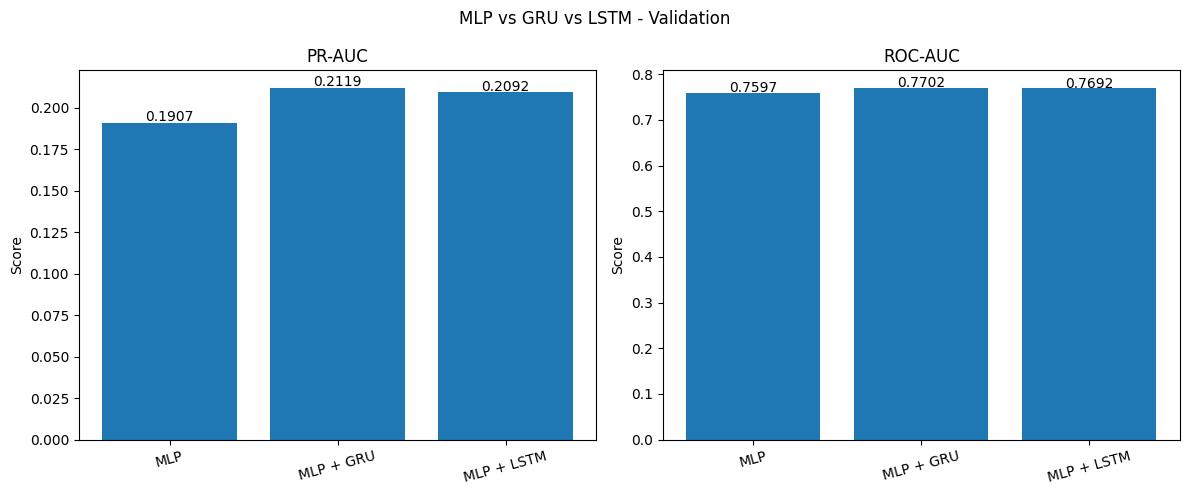

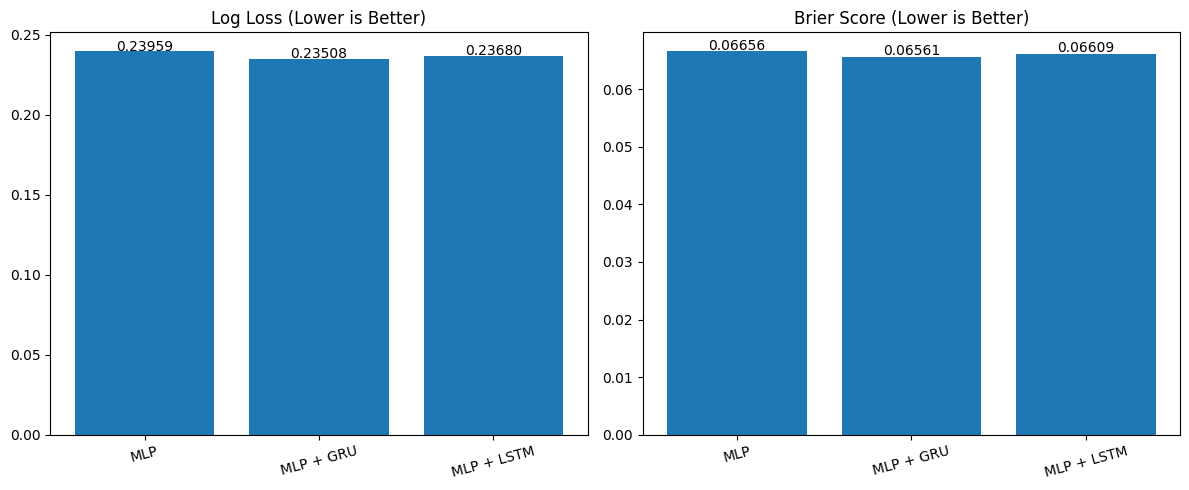

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# نتایج سه مدل روی Validation
comparison = pd.DataFrame({
    'MLP': {
        'PR-AUC': 0.19070,
        'ROC-AUC': 0.75966,
        'Log Loss': 0.23959,
        'Brier Score': 0.06656
    },

    'MLP + GRU': {
        'PR-AUC': 0.211871,
        'ROC-AUC': 0.77025,
        'Log Loss': 0.23508,
        'Brier Score': 0.06561
    },

    'MLP + LSTM': {
        'PR-AUC': 0.209195,
        'ROC-AUC': 0.76922,
        'Log Loss': 0.23680,
        'Brier Score': 0.06609
    }
})

print("Three Model Comparison - Validation")
display(comparison.round(5))


# درصد بهبود نسبت به MLP
improvement = pd.DataFrame(index=comparison.index)

for model_name in ['MLP + GRU', 'MLP + LSTM']:

    values = []

    for metric in comparison.index:

        baseline = comparison.loc[metric, 'MLP']
        new_value = comparison.loc[metric, model_name]

        if metric in ['PR-AUC', 'ROC-AUC']:
            gain = (new_value - baseline) / baseline * 100
        else:
            gain = (baseline - new_value) / baseline * 100

        values.append(gain)

    improvement[model_name] = values

print("\nImprovement over MLP (%)")
display(improvement.round(3))


# --------------------------------
# نمودار PR-AUC و ROC-AUC
# --------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(
    axes, ['PR-AUC', 'ROC-AUC']
):

    values = comparison.loc[metric]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(metric)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', rotation=15)

    for bar, value in zip(bars, values.values):

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.001,
            f'{value:.4f}',
            ha='center'
        )

plt.suptitle('MLP vs GRU vs LSTM - Validation')
plt.tight_layout()
plt.savefig('three_models_ranking.png', dpi=300)
plt.show()


# --------------------------------
# نمودار Log Loss و Brier Score
# --------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(
    axes, ['Log Loss', 'Brier Score']
):

    values = comparison.loc[metric]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(metric + ' (Lower is Better)')
    ax.tick_params(axis='x', rotation=15)

    for bar, value in zip(bars, values.values):

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.0003,
            f'{value:.5f}',
            ha='center'
        )

plt.tight_layout()
plt.savefig('three_models_error_metrics.png', dpi=300)
plt.show()


# ذخیره جدول
comparison.to_csv(
    'three_models_validation_comparison.csv'
)

improvement.to_csv(
    'three_models_improvement.csv'
)


In [ ]:

import numpy as np
from sklearn.metrics import average_precision_score

# برچسب‌های Validation
y_val = y_all[n_train:].reshape(-1).astype(np.int8)

# خروجی بهترین مدل‌ها
gru_scores = np.asarray(
    best_valid_logits_gru
).reshape(-1)

lstm_scores = np.asarray(
    best_valid_logits_lstm
).reshape(-1)

assert len(y_val) == len(gru_scores) == len(lstm_scores)

# شناسه کاربران Validation
val_users = user_ids_all[n_train:]

unique_users, user_codes = np.unique(
    val_users,
    return_inverse=True
)

# --------------------------------
# آماده‌سازی سریع PR-AUC
# --------------------------------

def prepare_ap(y, scores, codes):

    order = np.argsort(-scores, kind='mergesort')

    sorted_scores = scores[order]

    starts = np.r_[
        0,
        np.flatnonzero(
            sorted_scores[1:] != sorted_scores[:-1]
        ) + 1
    ]

    return (
        codes[order],
        y[order].astype(np.float64),
        starts
    )


def weighted_ap(cache, user_weights):

    codes, labels, starts = cache

    row_weights = user_weights[codes]

    tp = np.add.reduceat(
        row_weights * labels, starts
    )

    total = np.add.reduceat(
        row_weights, starts
    )

    total_positive = tp.sum()

    if total_positive <= 0:
        return np.nan

    cumulative_tp = np.cumsum(tp)
    cumulative_total = np.cumsum(total)

    precision = np.divide(
        cumulative_tp,
        cumulative_total,
        out=np.zeros_like(cumulative_tp),
        where=cumulative_total > 0
    )

    return np.sum(
        (tp / total_positive) * precision
    )


# آماده‌سازی دو مدل
gru_cache = prepare_ap(
    y_val, gru_scores, user_codes
)

lstm_cache = prepare_ap(
    y_val, lstm_scores, user_codes
)

# کنترل صحت محاسبه
gru_ap = average_precision_score(y_val, gru_scores)
lstm_ap = average_precision_score(y_val, lstm_scores)

assert np.isclose(
    weighted_ap(gru_cache, np.ones(len(unique_users))),
    gru_ap,
    atol=1e-10
)

assert np.isclose(
    weighted_ap(lstm_cache, np.ones(len(unique_users))),
    lstm_ap,
    atol=1e-10
)

print("PR-AUC verification passed.")
print("GRU PR-AUC:", gru_ap)
print("LSTM PR-AUC:", lstm_ap)


# --------------------------------
# Bootstrap با 2000 تکرار
# --------------------------------

N_BOOT = 2000
rng = np.random.default_rng(42)

differences = []
relative_gains = []

n_users = len(unique_users)

while len(differences) < N_BOOT:

    # نمونه‌گیری کاربران با جایگزینی
    sampled_users = rng.integers(
        0,
        n_users,
        size=n_users
    )

    user_weights = np.bincount(
        sampled_users,
        minlength=n_users
    )

    # ارزیابی هر دو مدل روی همان کاربران
    ap_gru = weighted_ap(
        gru_cache, user_weights
    )

    ap_lstm = weighted_ap(
        lstm_cache, user_weights
    )

    if not np.isfinite(ap_gru) or not np.isfinite(ap_lstm):
        continue

    differences.append(ap_gru - ap_lstm)

    relative_gains.append(
        (ap_gru / ap_lstm - 1) * 100
    )

    if len(differences) % 200 == 0:
        print(
            f"Bootstrap: {len(differences)}/{N_BOOT}"
        )


# --------------------------------
# فاصله اطمینان 95 درصد
# --------------------------------

ci_difference = np.percentile(
    differences, [2.5, 97.5]
)

ci_relative = np.percentile(
    relative_gains, [2.5, 97.5]
)

observed_difference = gru_ap - lstm_ap

observed_relative = (
    (gru_ap / lstm_ap) - 1
) * 100


# گزارش نهایی
print("\n========== GRU vs LSTM ==========")

print("Bootstrap repetitions:", N_BOOT)

print(f"\nGRU PR-AUC: {gru_ap:.5f}")
print(f"LSTM PR-AUC: {lstm_ap:.5f}")

print(f"\nAbsolute Difference: {observed_difference:.5f}")
print(
    f"95% CI: [{ci_difference[0]:.5f}, "
    f"{ci_difference[1]:.5f}]"
)

print(f"\nRelative Improvement: {observed_relative:.2f}%")
print(
    f"95% CI: [{ci_relative[0]:.2f}%, "
    f"{ci_relative[1]:.2f}%]"
)

print(
    "\nNon-positive improvements:",
    np.sum(np.asarray(differences) <= 0)
)


PR-AUC verification passed.
GRU PR-AUC: 0.21187125453804495
LSTM PR-AUC: 0.209195127591223
Bootstrap: 200/2000
Bootstrap: 400/2000
Bootstrap: 600/2000
Bootstrap: 800/2000
Bootstrap: 1000/2000
Bootstrap: 1200/2000
Bootstrap: 1400/2000
Bootstrap: 1600/2000
Bootstrap: 1800/2000
Bootstrap: 2000/2000

========== GRU vs LSTM ==========
Bootstrap repetitions: 2000

GRU PR-AUC: 0.21187
LSTM PR-AUC: 0.20920

Absolute Difference: 0.00268
95% CI: [0.00149, 0.00388]

Relative Improvement: 1.28%
95% CI: [0.70%, 1.86%]

Non-positive improvements: 0
